#NAMA : CAHYA NIRWANA YOZA
#NIM : 09011182227025
#KELAS : SK6A
#MATA KULIAH : PRAKTIKUM MACHINE LEARNING
#UJIAN AKHIR SEMESTER

In [ ]:
!pip install vaderSentiment
!pip install textblob
!pip install pivottablejs
!pip install ydata-profiling
!pip install pyspellchecker
!pip install scattertext
!pip install nltk
!pip install -U kaleido
!pip install twython
!pip install colorama


Perintah-perintah di atas menginstal berbagai pustaka Python yang berguna untuk analisis teks, visualisasi, dan pemrosesan data. Berikut deskripsinya:

1. vaderSentiment – Pustaka untuk analisis sentimen berbasis aturan, cocok untuk teks media sosial.
2. textblob – Pustaka NLP yang menyediakan analisis sentimen, koreksi ejaan, dan ekstraksi frasa.
3. pivottablejs – Pustaka untuk membuat tabel pivot interaktif langsung dari DataFrame Pandas.
4. ydata-profiling – Digunakan untuk membuat laporan eksplorasi data otomatis dari Pandas DataFrame.
5. pyspellchecker – Pustaka untuk koreksi ejaan berbasis probabilitas.
6. scattertext – Digunakan untuk eksplorasi dan visualisasi data teks berbasis frekuensi kata.
7. nltk – Pustaka NLP (Natural Language Toolkit) untuk tokenisasi, stemming, stopwords, dll.
8. kaleido – Backend statis untuk menyimpan visualisasi Plotly dalam format gambar (PNG, SVG, dll.).
9. twython – API wrapper untuk berinteraksi dengan Twitter menggunakan Python.
10. colorama – Pustaka untuk menambahkan warna pada output terminal, sering digunakan dalam logging.

In [ ]:
import re
import dateutil.parser
import nltk
import plotly.offline as pyo
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go
import scattertext as st
import random

import string
import pandas as pd # This line imports pandas, which is now installed.
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from textblob import TextBlob
from plotly.subplots import make_subplots
from nltk.stem import PorterStemmer, WordNetLemmatizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from pivottablejs import pivot_ui
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.core.display import display
from datetime import datetime
from nltk import tokenize
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from pandas_profiling import ProfileReport
from ydata_profiling import ProfileReport
from tqdm.notebook import tqdm
from collections import Counter
from wordcloud import WordCloud
from google.colab import files
from textblob import TextBlob
from IPython.display import IFrame
from wordcloud import WordCloud, ImageColorGenerator
from nltk.corpus import stopwords

# Downloading periphrals
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

import warnings
warnings.filterwarnings('ignore')

Kode Python ini mengimpor berbagai pustaka untuk analisis data, pemrosesan teks, dan visualisasi, termasuk pandas, numpy, seaborn, dan matplotlib untuk manipulasi serta visualisasi data. Plotly digunakan untuk grafik interaktif, sementara TextBlob, NLTK, dan VADER Sentiment Analyzer mendukung pemrosesan bahasa alami (NLP). Selain itu, scikit-learn menyediakan alat untuk machine learning seperti train_test_split, accuracy_score, dan TfidfVectorizer. Kode juga mengunduh dataset VADER lexicon dan stopwords dari NLTK serta menggunakan wordcloud untuk representasi visual teks. Terakhir, terdapat peringatan bahwa pandas_profiling akan dihentikan dan digantikan oleh ydata_profiling.

In [ ]:
# Membaca file CSV (gunakan nama file yang diunggah)
df = pd.read_csv("chatgpt_daily_tweetss.csv")

 Fungsi input dan output di atas memuat data dari file CSV bernama chatgpt_daily_tweets.csv ke dalam sebuah DataFrame menggunakan pustaka pandas. Dengan menyimpan data dalam bentuk DataFrame, pengguna dapat dengan mudah melakukan analisis, manipulasi, serta visualisasi data. File CSV yang dipanggil harus tersedia dalam direktori kerja saat ini atau path lengkapnya harus disertakan agar proses pembacaan berhasil tanpa error.

In [ ]:
df = pd.DataFrame(df)

# Buat profil laporan eksplorasi data
df_profile = ProfileReport(df, title="Profil Data")

# Tampilkan di notebook
df_profile.to_notebook_iframe()

Fungsi input dan output di atas ialah  untuk melakukan Exploratory Data Analysis (EDA) secara otomatis menggunakan pustaka ydata_profiling (sebelumnya dikenal sebagai pandas_profiling). Proses ini dimulai dengan mengonversi DataFrame df menjadi sebuah objek profil menggunakan ProfileReport(df, title="Profil Data"). Laporan tersebut kemudian ditampilkan langsung di notebook menggunakan df_profile.to_notebook_iframe(). Dari hasil analisis yang ditampilkan, dataset memiliki 41.003 observasi dan 20 variabel, dengan sekitar 7,8% nilai yang hilang. Data terdiri dari berbagai tipe, termasuk text, numeric, datetime, dan boolean. Beberapa kolom seperti user_followers_count, retweet_count, dan like_count memiliki distribusi yang miring (skewed), menunjukkan adanya beberapa nilai ekstrem (outliers). Selain itu, beberapa variabel memiliki persentase nol yang cukup tinggi, seperti reply_count dengan 89,1% nilai nol. Laporan ini juga menyertakan analisis korelasi antar variabel, visualisasi nilai yang hilang, serta distribusi data untuk membantu memahami pola dalam dataset sebelum melakukan analisis lebih lanjut atau pemodelan.

In [ ]:
from IPython.display import HTML

# Contoh: Load dataset DJIA
upload_DJIA_table = pd.read_csv("chatgpt_daily_tweetss.csv")  # Gantilah dengan dataset Anda

# Simpan pivot table ke file HTML
pivot_ui(upload_DJIA_table, outfile_path
         ='pivot_table.html')

# Tampilkan file HTML di Google Colab
display(HTML('pivot_table.html'))

Fungsi Input dan output diatas ialah Pertama, dataset dimuat menggunakan pd.read_csv("chatgpt_daily_tweets.csv"), yang mengasumsikan bahwa dataset berisi data harian terkait ChatGPT. Kemudian, fungsi pivot_ui digunakan untuk membuat tabel pivot interaktif dari dataset yang diunggah, memungkinkan pengguna untuk mengeksplorasi dan menganalisis data dengan mudah. Hasil tabel pivot disimpan dalam file HTML dengan nama pivot_table.html, yang kemudian ditampilkan dalam Google Colab menggunakan display(HTML('pivot_table.html')). Dengan cara ini, pengguna dapat melakukan analisis data secara dinamis tanpa perlu menulis kode tambahan untuk agregasi atau visualisasi manual.

In [ ]:
df.head()

Input di atas menampilkan 5 baris petama dan 20 kolom dalam dataset sebelum di preprocessing

In [ ]:
df.info()

Input diatas menjelaskan tentang tipe data, untuk tipe data object itu untuk type data teks atau string, disini untuk object nya terdiri dari 12 kolom, dan tipe data float64 itu merupakan tipe data berbentuk pecahan disini float nya terdiri dari 8 kolom.

In [ ]:
df.isnull().sum()

 Inputan diatas berfungsi untuk melihat kolom yang hilang (Missing Value), disini terdiri dari 3 kolom missing value yaitu kolom user location, user description dan yang paling banyak missing value nya di source

In [ ]:
df.describe()


Inputan di atas mendeskripsikan ringkasan statistik untuk kolom numerik dalam DataFrame. Setiap kolom memiliki beberapa metrik, seperti count (jumlah nilai yang tersedia), mean (nilai rata-rata), std (standar deviasi, mengukur sebaran data), min (nilai minimum), serta 25%, 50% (median), dan 75% yang menunjukkan kuartil data. Misalnya, kolom user_followers_count memiliki rata-rata 7.138 (sekitar 7 ribu), tetapi standar deviasi yang sangat tinggi (181,946) menunjukkan ada akun dengan jumlah pengikut yang jauh lebih besar dibandingkan rata-rata. Nilai min dan max menunjukkan kisaran data, seperti like_count yang memiliki nilai maksimum 9,170 tetapi median 0, artinya sebagian besar data memiliki like_count yang sangat rendah atau nol. Selain itu, kolom source hanya berisi nilai NaN, menunjukkan bahwa tidak ada data yang tersedia di kolom tersebut. Dengan memahami statistik ini, kita bisa mengidentifikasi pola dalam data serta potensi outlier yang mungkin mempengaruhi analisis.

In [ ]:
df.describe(include='object')

Ringkasan statistik untuk kolom bertipe data objek (string atau kategori). Kolom count menunjukkan jumlah data non-null dalam setiap kategori, misalnya tweet_id, tweet_created, dan tweet_extracted masing-masing memiliki 41.003 data yang tidak kosong. Kolom unique menunjukkan jumlah nilai unik dalam setiap kolom, seperti text memiliki 24.513 variasi unik, dan lang memiliki 57 bahasa yang berbeda. Kolom top menampilkan nilai yang paling sering muncul (modus) dalam setiap kolom, misalnya text yang paling sering muncul adalah retweet dari pengguna tertentu, sedangkan bahasa yang paling umum adalah en (bahasa Inggris). Kolom freq menunjukkan frekuensi dari nilai yang paling umum tersebut, misalnya bahasa Inggris (en) muncul sebanyak 19.711 kali, dan akun dengan username AI_Dev_News adalah yang paling sering muncul sebanyak 42 kali. Kolom user_verified menunjukkan bahwa nilai yang paling umum adalah False, dengan frekuensi 38.498, artinya mayoritas akun dalam dataset ini tidak terverifikasi. Analisis ini menunjukkan bahwa dataset berisi banyak data duplikat atau sering diulang, seperti retweet dan akun yang berulang kali muncul.









In [ ]:
df.columns

 Inputan di atas mendeskripsikan terdapat 20 judul kolom dalam dataset

In [ ]:
for column in df.columns:
    num_distinct_values = len(df[column].unique())
    print(f"{column}: {num_distinct_values} distinct values")

Jumlah nilai unik dalam setiap kolom dataset menggunakan metode .unique(). Dari hasil yang diperoleh, dapat dilihat bahwa tweet_id memiliki 38.959 nilai unik dari total 41.003 data, menunjukkan adanya beberapa duplikasi. Kolom tweet_created memiliki 28.364 nilai unik, yang berarti beberapa tweet dibuat pada waktu yang sama. text memiliki 24.513 variasi unik, menunjukkan banyak tweet yang memiliki isi yang sama, kemungkinan karena retweet. Kolom lang hanya memiliki 57 nilai unik, menunjukkan bahwa tweet dalam dataset ini berasal dari berbagai bahasa tetapi tidak terlalu banyak variasinya. user_id memiliki 36.394 nilai unik, sementara user_name dan user_username memiliki masing-masing 35.614 dan 36.418 nilai unik, yang menunjukkan adanya beberapa akun dengan nama pengguna berbeda tetapi kemungkinan merujuk ke orang yang sama. user_followers_count dan user_following_count memiliki ribuan variasi unik, menunjukkan perbedaan besar dalam jumlah pengikut dan jumlah akun yang diikuti oleh pengguna. source hanya memiliki satu nilai unik, menunjukkan bahwa semua tweet berasal dari sumber yang sama. Untuk metrik keterlibatan seperti retweet_count, like_count, reply_count, dan impression_count, jumlah nilai uniknya bervariasi, dengan like_count memiliki 203 nilai unik dan impression_count memiliki 1.792 nilai unik, yang menunjukkan tingkat variasi keterlibatan pengguna terhadap tweet yang ada. Data ini bisa digunakan untuk analisis lebih lanjut, seperti pola keterlibatan pengguna dan distribusi bahasa dalam dataset.









In [ ]:
df.duplicated().sum()

untuk menghitung jumlah baris duplikat dalam DataFrame df



#VISUALISASI EDA

In [ ]:
df.hist(figsize=(25, 20), bins=30, edgecolor='black')
plt.suptitle("Distribusi Data Numerik", fontsize=16)
plt.show()

Kode ini digunakan untuk membuat histogram dari setiap kolom numerik dalam DataFrame df. Fungsi df.hist() secara otomatis menghasilkan histogram untuk semua kolom numerik, dengan ukuran gambar sebesar 25x20 inci (figsize=(25, 20)) agar tampilan lebih jelas. Histogram dibagi menjadi 30 bin (bins=30), dan setiap batang memiliki tepi berwarna hitam (edgecolor='black') untuk memperjelas batas antar bin. Judul utama grafik ditambahkan dengan plt.suptitle("Distribusi Data Numerik", fontsize=16), lalu grafik ditampilkan menggunakan plt.show(). Kode ini membantu dalam eksplorasi data dengan memvisualisasikan distribusi nilai dalam setiap kolom numerik DataFrame.

In [ ]:
# Pilih hanya kolom kategorikal
df_categorical = df.select_dtypes(include=['object'])

# Tentukan jumlah maksimum kategori yang akan divisualisasikan per kolom
max_categories = 10

# Loop untuk membuat visualisasi per kolom
for col in df_categorical.columns:
    plt.figure(figsize=(10, 5))

    # Ambil kategori terbanyak (agar tidak terlalu banyak kategori)
    top_categories = df[col].value_counts().nlargest(max_categories)

    # Buat barplot
    sns.barplot(x=top_categories.index, y=top_categories.values, palette="viridis")

    # Tambahkan judul dan label
    plt.title(f"Distribusi {col} (Top {max_categories})")
    plt.xlabel(col)
    plt.ylabel("Jumlah")
    plt.xticks(rotation=45)  # Rotasi label agar lebih terbaca

    plt.show()

Memvisualisasikan distribusi data dari kolom-kolom kategorikal dalam DataFrame df. Pertama, dipilih hanya kolom dengan tipe data kategorikal (object) menggunakan df.select_dtypes(include=['object']). Kemudian, ditentukan batas maksimum kategori yang akan divisualisasikan per kolom (max_categories = 10) agar grafik tidak terlalu penuh. Dalam loop, setiap kolom kategorikal divisualisasikan menggunakan barplot, dengan hanya menampilkan 10 kategori terbanyak berdasarkan jumlah kemunculannya (value_counts().nlargest(max_categories)). Grafik dibuat dengan ukuran 10x5 inci, menggunakan palet warna "viridis", serta diberi judul dan label sumbu yang sesuai. Label sumbu X juga diputar (rotation=45) agar lebih mudah dibaca, dan grafik ditampilkan menggunakan plt.show().









##OUTLIER

1. Boxplot of true
Boxplot ini menunjukkan distribusi dari nilai target (true) dalam data. Karena boxplot hanya memperlihatkan dua nilai (kemungkinan 0 dan 1), serta seluruh boxplot terletak pada nilai 1, ini mengindikasikan bahwa data yang digunakan untuk analisis ini mayoritas — bahkan mungkin seluruhnya — berlabel sebagai kelas positif (1). Ini bisa menunjukkan ketidakseimbangan kelas atau bahwa subset ini hanya terdiri dari sampel positif.

2. Boxplot of score
Boxplot ini menggambarkan distribusi dari skor prediksi model (biasanya probabilitas prediksi terhadap kelas positif). Mayoritas skor berada di bawah 0.2, yang mengindikasikan bahwa model cenderung memberikan prediksi probabilitas yang rendah meskipun data sebenarnya termasuk kelas positif (berdasarkan plot sebelumnya). Ini bisa menunjukkan underconfidence pada model atau bahwa model kesulitan mengenali pola dari kelas positif dengan baik.

3. Boxplot of cumulative_data_fraction
Boxplot ini menunjukkan proporsi kumulatif data. Distribusinya simetris antara 0 hingga 1, yang sesuai dengan ekspektasi karena ini menunjukkan akumulasi data dari awal hingga akhir saat dihitung secara bertahap. Ini adalah representasi normal dan tidak menunjukkan anomali berarti.

4. Boxplot of cumulative_gain
Boxplot ini menggambarkan kenaikan kumulatif dari metrik target saat data diurutkan berdasarkan skor prediksi. Median mendekati 1 menunjukkan bahwa bagian atas daftar yang diprediksi oleh model mengandung sebagian besar instance positif. Namun, banyak outlier di bagian bawah (mendekati 0), yang menunjukkan bahwa ada sebagian besar data yang kontribusinya kecil terhadap gain kumulatif, kemungkinan karena skor prediksinya rendah.

5. Boxplot of lift
Plot ini menunjukkan efektivitas model dalam mengidentifikasi kelas positif dibandingkan dengan acak. Median lift sekitar 2 menunjukkan bahwa model setidaknya dua kali lebih baik daripada tebakan acak pada bagian tertentu dari data. Namun, terdapat outlier besar (mendekati 8), yang menunjukkan bahwa di segmen atas tertentu (misalnya top 10%), model bekerja sangat baik. Variasi yang tinggi ini mengindikasikan performa model sangat tergantung pada threshold atau segmen data yang dipilih.



In [ ]:
import scipy.stats as stats # Import the stats module from scipy

# Tentukan kolom numerik
numerical_cols = df.select_dtypes(include=[np.number]).columns

# Hitung Z-score untuk setiap nilai dalam kolom numerik
z_scores = np.abs(stats.zscore(df[numerical_cols]))

# Tentukan threshold untuk outlier
threshold = 3
outliers_z = (z_scores > threshold)

# Ambil baris yang memiliki setidaknya satu nilai outlier
outlier_data_z = df[outliers_z.any(axis=1)]

# Tampilkan jumlah outlier
print(f"Total Outliers Detected: {outlier_data_z.shape[0]}\n")

# Menampilkan beberapa contoh outlier
print("Sample Outliers:")
print(outlier_data_z.head())

1. Total Outliers Detected
Sebanyak 32 outlier terdeteksi dalam dataset berdasarkan metrik yang digunakan (kemungkinan melalui boxplot, z-score, atau metode IQR). Ini menunjukkan bahwa terdapat sejumlah kecil data yang memiliki karakteristik ekstrem atau berbeda secara signifikan dari mayoritas data. Outlier ini perlu dianalisis lebih lanjut karena bisa merepresentasikan noise, kesalahan input, atau justru informasi penting (seperti kasus langka).

2. Kolom true
Semua outlier yang ditampilkan memiliki nilai true = 1, yang berarti semua instance outlier berasal dari kelas positif. Ini menunjukkan bahwa nilai ekstrem yang dideteksi berasal dari distribusi kelas positif, yang mengindikasikan bahwa meskipun label benar adalah positif, karakteristik metrik lainnya (seperti skor, gain, lift) membuat mereka tampak berbeda dari sampel positif lainnya.

3. Kolom score
Seluruh contoh outlier memiliki skor prediksi sebesar 1.0, yaitu skor maksimal. Hal ini mengindikasikan bahwa model sangat yakin bahwa sampel tersebut termasuk dalam kelas positif. Namun, kenyataan bahwa skor ini dianggap sebagai outlier menunjukkan bahwa skor 1.0 sangat jarang muncul, dan model biasanya tidak memberikan keyakinan penuh. Skor 1.0 ini bisa menjadi tanda overconfidence atau hasil dari data yang sangat mirip dengan data pelatihan.

4. Kolom cumulative_data_fraction
Nilai pada kolom ini sangat kecil (antara 0.00000 hingga 0.00100), yang menunjukkan bahwa instance-instance ini berada di awal urutan data yang digunakan untuk menghitung cumulative gain dan lift — artinya model menganggap mereka sebagai yang paling penting atau paling "positif". Ini juga menjelaskan mengapa mereka memiliki skor tinggi (1.0).

5. Kolom cumulative_gain
Nilai cumulative gain di sini relatif rendah (misalnya 0.000955 hingga 0.003820), yang tampak aneh mengingat skor prediksi sangat tinggi. Ini dapat mengindikasikan bahwa meskipun model sangat yakin, kontribusi instance tersebut terhadap peningkatan total gain masih kecil, mungkin karena bobot atau nilai relatifnya kecil dibandingkan instance lain. Hal ini bisa menunjukkan bahwa high confidence tidak selalu berarti kontribusi besar terhadap metrik bisnis atau model evaluation.

6. Kolom lift
Nilai lift bervariasi, dari 0.0 hingga sekitar 7.6. Instance dengan lift 0.0 menunjukkan bahwa meskipun model sangat yakin (score = 1.0), kontribusinya terhadap peningkatan efektivitas klasifikasi (dibandingkan tebakan acak) sangat rendah — kemungkinan besar karena posisinya paling awal atau kontribusi terhadap target kecil. Sebaliknya, instance dengan lift 7.6 sangat efektif dalam meningkatkan prediksi dibandingkan acak, dan sangat berharga dalam konteks pengambilan keputusan.



##KORELASI NUMERIK

In [ ]:
# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=np.number)

# Korelasi antar kolom numerik
corr_matrix = numeric_df.corr()

# Visualisasi heatmap korelasi numerik
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Numerik")
plt.show()

Menghitung dan memvisualisasikan korelasi antara kolom-kolom numerik dalam DataFrame df menggunakan heatmap. Pertama, hanya kolom numerik yang dipilih dengan df.select_dtypes(include=np.number), lalu matriks korelasinya dihitung menggunakan numeric_df.corr(). Hasil korelasi divisualisasikan dalam bentuk heatmap menggunakan sns.heatmap(), dengan anotasi nilai korelasi (annot=True), skema warna "coolwarm", format angka dua desimal (fmt=".2f"), dan garis pemisah antar sel (linewidths=0.5). Grafik diberi judul "Heatmap Korelasi Numerik" dan ditampilkan menggunakan plt.show(), sehingga memudahkan analisis hubungan antar variabel numerik dalam dataset.

#PRE-PROCESSING

In [ ]:
# Inisialisasi alat-alat yang diperlukan
sns.set_style('darkgrid')
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer # Import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer() # Initialize SIA
from spellchecker import SpellChecker # Import SpellChecker
spell = SpellChecker()
pyo.init_notebook_mode()

Menginisialisasi beberapa alat untuk analisis teks dan visualisasi data. Pertama, sns.set_style('darkgrid') digunakan untuk mengatur gaya tampilan grafik dengan latar belakang grid menggunakan Seaborn. Kemudian, SentimentIntensityAnalyzer dari pustaka VADER Sentiment diimpor dan diinisialisasi sebagai sia, yang berfungsi untuk menganalisis sentimen teks berdasarkan skor positif, negatif, dan netral. Selain itu, pustaka SpellChecker diimpor dan diinisialisasi sebagai spell untuk mendeteksi serta memperbaiki kesalahan ejaan dalam teks. Terakhir, pyo.init_notebook_mode() digunakan untuk mengaktifkan mode tampilan Plotly di dalam Jupyter Notebook agar grafik interaktif dapat ditampilkan langsung. Kode ini umumnya digunakan dalam analisis teks, seperti analisis sentimen dan pemeriksaan ejaan, untuk meningkatkan akurasi pemrosesan data sebelum dianalisis lebih lanjut.


In [ ]:
df = df.drop(columns=['tweet_id', 'tweet_extracted','user_id', 'user_location', 'user_description','user_created',	'user_followers_count', 'user_following_count', 'user_tweet_count', 'user_verified', 'source', 'impression_count'	  ])

Inputan diatas berfungsi untuk Menghapus kolom yang tdak ingin di gunanakan dalam sentiment

In [ ]:
#2.Preprocessing Teks pada Kolom
# Fungsi untuk membersihkan teks
def clean_text(text):
    text = str(text).lower()  # Konversi ke huruf kecil
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)  # Hapus URL
    text = re.sub(r'\@w+|\#', '', text)  # Hapus mention dan hashtag
    text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
    text = re.sub(r'\d+', '', text)  # Hapus angka
    return text

# Terapkan fungsi cleaning
df['clean_text'] = df['text'].apply(clean_text)

 Inputan di atas berfungsi untuk membersihkan teks dalam suatu kolom dengan berbagai teknik preprocessing. Pertama, teks dikonversi menjadi huruf kecil agar konsistensi tetap terjaga. Selanjutnya, fungsi ini menghapus URL menggunakan ekspresi reguler, menghilangkan mention (@) dan hashtag (#), serta menghapus tanda baca dengan str.translate(). Selain itu, angka juga dihapus menggunakan ekspresi reguler agar hanya teks murni yang tersisa. Setelah fungsi clean_text didefinisikan, proses pembersihan ini diterapkan pada setiap nilai dalam kolom text menggunakan .apply(), dan hasilnya disimpan dalam kolom baru bernama clean_text, sehingga teks menjadi lebih bersih dan siap untuk analisis lebih lanjut.

In [ ]:
import nltk
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))
ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Fungsi untuk tokenisasi, hapus stopwords, dan stemming/lemmatization
def preprocess_text(text):
    words = word_tokenize(text)  # Tokenisasi
    words = [word for word in words if word not in stop_words]  # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words]  # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing
df['processed_text'] = df['clean_text'].apply(preprocess_text)

Kode ini bertujuan untuk melakukan preprocessing teks dengan tiga langkah utama: tokenisasi, penghapusan stopwords, dan lemmatization. Pertama, modul nltk mengunduh dataset punkt dan wordnet yang diperlukan untuk tokenisasi dan lemmatization. Kemudian, daftar stopwords bahasa Inggris diambil menggunakan stopwords.words('english'), sementara PorterStemmer() dan WordNetLemmatizer() diinisialisasi untuk stemming dan lemmatization. Fungsi preprocess_text melakukan tiga tahap utama, yaitu: tokenisasi teks menggunakan word_tokenize(), menghapus kata-kata umum (stopwords), dan melakukan lemmatization menggunakan lemmatizer.lemmatize() untuk mengubah kata menjadi bentuk dasarnya. Akhirnya, fungsi ini diterapkan pada kolom clean_text, dan hasilnya disimpan dalam kolom baru bernama processed_text, sehingga teks siap digunakan untuk analisis lebih lanjut.

In [ ]:
#4.Konversi Teks ke Vektor (TF-IDF)
vectorizer = TfidfVectorizer(max_features=500)  # Ambil 500 fitur terpenting
tfidf_matrix = vectorizer.fit_transform(df['processed_text'])

# Konversi ke DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out())

# Gabungkan dengan dataset utama
df = pd.concat([df, tfidf_df], axis=1)

Kode ini bertujuan untuk mengubah teks menjadi representasi numerik menggunakan metode TF-IDF (Term Frequency-Inverse Document Frequency). TfidfVectorizer(max_features=500) digunakan untuk mengekstrak 500 fitur (kata) terpenting berdasarkan bobot TF-IDF dari kolom processed_text. Kemudian, fit_transform(df['processed_text']) mengubah teks menjadi matriks TF-IDF, yang kemudian dikonversi ke dalam bentuk DataFrame dengan pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out()). Selanjutnya, DataFrame hasil TF-IDF digabungkan dengan dataset utama df menggunakan pd.concat([df, tfidf_df], axis=1), sehingga setiap teks dalam dataset kini memiliki representasi numerik berdasarkan bobot kata-katanya, yang bisa digunakan untuk analisis atau pemodelan machine learning lebih lanjut.









In [ ]:
#5. Ekstraksi Fitur Waktu dari tweet_created
#Pastikan kolom waktu dalam format datetime
df['tweet_created'] = pd.to_datetime(df['tweet_created'])

# Buat fitur waktu baru
df['tweet_hour'] = df['tweet_created'].dt.hour  # Ambil jam
df['tweet_day'] = df['tweet_created'].dt.day  # Ambil hari
df['tweet_month'] = df['tweet_created'].dt.month  # Ambil bulan

Kode ini digunakan untuk ekstraksi fitur waktu dari kolom tweet_created, yang berisi informasi waktu pembuatan tweet. Pertama, pd.to_datetime(df['tweet_created']) memastikan bahwa data dalam kolom tersebut dikonversi ke format datetime agar dapat diolah lebih lanjut. Kemudian, beberapa fitur waktu diekstrak: df['tweet_hour'] mengambil informasi jam, df['tweet_day'] mengambil informasi hari dalam satu bulan, dan df['tweet_month'] mengambil informasi bulan dari tanggal tweet dibuat. Fitur-fitur ini berguna untuk analisis tren waktu, seperti melihat pola aktivitas pengguna berdasarkan jam, hari, atau bulan tertentu.









In [ ]:
#6.Buat Fitur total_engagement & high_engagement
# Hitung total engagement
# Removing 'impression_count' as it has been dropped
df['total_engagement'] = df['retweet_count'] + df['like_count'] + df['reply_count']
#df['total_engagement'] = df['retweet_count'] + df['like_count'] + df['reply_count'] + df['impression_count']

# Buat kategori high engagement (1 jika lebih dari median, 0 jika kurang)
df['high_engagement'] = (df['total_engagement'] > df['total_engagement'].median()).astype(int)

Kode ini digunakan untuk membuat dua fitur baru yang berkaitan dengan keterlibatan pengguna dalam tweet.

1. Fitur total engagement dihitung dengan menjumlahkan tiga kolom yang mewakili interaksi pengguna dengan tweet: retweet_count, like_count, dan reply_count. Ini memberikan gambaran total interaksi yang diterima oleh sebuah tweet.

2.  Fitur high engagement adalah kategori biner yang menandakan apakah total keterlibatan lebih tinggi dari median total keterlibatan. Jika total_engagement lebih besar dari median nilai total keterlibatan, maka nilai high_engagement akan di-set ke 1, menandakan bahwa tweet tersebut memiliki keterlibatan tinggi. Sebaliknya, jika lebih kecil dari median, nilai high_engagement di-set ke 0. Fitur ini bisa digunakan untuk analisis lebih lanjut tentang tweet dengan keterlibatan tinggi dibandingkan dengan yang rendah.

In [ ]:
#7.Sentiment Label
sia = SentimentIntensityAnalyzer()

def get_sentiment_label(text):
    """Gets the sentiment label for a given text using VADER."""
    sentiment_scores = sia.polarity_scores(text)
    compound_score = sentiment_scores['compound']

    if compound_score >= 0.05:
        return 'positive'
    elif compound_score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['sentiment_label'] = df['processed_text'].apply(get_sentiment_label)

 implementasi analisis sentimen berbasis lexicon menggunakan VADER (Valence Aware Dictionary and sEntiment Reasoner) dari pustaka nltk. Tujuan dari kode ini adalah untuk memberikan label sentimen—positif, negatif, atau netral—pada setiap teks dalam sebuah dataset. Proses dimulai dengan inisialisasi objek SentimentIntensityAnalyzer() yang digunakan untuk menghitung skor sentimen dari setiap teks. Kemudian, dibuat fungsi get_sentiment_label() yang mengambil teks sebagai input dan menghasilkan skor polaritas menggunakan metode polarity_scores(). Fokus utamanya adalah skor 'compound', yang merupakan skor gabungan dari seluruh aspek sentimen dan nilainya berada dalam rentang -1 (paling negatif) hingga +1 (paling positif). Berdasarkan nilai ini, teks diklasifikasikan: jika skor lebih besar atau sama dengan 0.05 maka diberi label ‘positive’, jika kurang dari atau sama dengan -0.05 maka ‘negative’, dan sisanya diberi label ‘neutral’. Fungsi ini kemudian diterapkan ke kolom processed_text dalam DataFrame df, dan hasil klasifikasinya disimpan dalam kolom baru sentiment_label.

In [ ]:
# 8. Encoding label kategori menjadi angka
from sklearn.preprocessing import LabelEncoder # Import LabelEncoder
le = LabelEncoder()
df['sentiment_label'] = le.fit_transform(df['sentiment_label'])

proses encoding label kategori menjadi angka menggunakan LabelEncoder dari pustaka sklearn.preprocessing. Proses ini penting saat ingin mengubah data kategorikal (dalam hal ini: label sentimen seperti "positive", "neutral", "negative") menjadi bentuk numerik, agar bisa digunakan oleh algoritma machine learning yang tidak bisa langsung menangani data dalam bentuk string.

In [ ]:
# Cek 5 baris pertama dari dataset setelah preprocessing
print("📌 Data Setelah Preprocessing:")
display(df.head())  # Untuk Jupyter Notebook
# atau gunakan df.head() jika di script biasa


Check 5 baris awal setelah di preprocessing

#EDA AFTER PRE PROCESSING

In [ ]:
specified_columns = ['tweet_hour', 'tweet_day', 'tweet_month', 'sentiment_label', 'total_engagement', 'high_engagement']
for col in specified_columns:
    total_unique_values = df[col].nunique()
    print(f'Total unique values for {col}: {total_unique_values}')

    top_values = df[col].value_counts()

    # Import 'Fore' from 'colorama' inside the loop
    from colorama import Fore

    colors = [Fore.RED, Fore.GREEN, Fore.YELLOW, Fore.BLUE, Fore.MAGENTA, Fore.CYAN, Fore.WHITE, Fore.LIGHTBLACK_EX, Fore.LIGHTRED_EX, Fore.LIGHTGREEN_EX]

    for i, (value, count) in enumerate(top_values.items()):
        color = colors[i % len(colors)]
        print(f'{color}{value}: {count}{Fore.RESET}')

    print('\n' + '=' * 30 + '\n')

Input dan output diatas berfungsi untuk menampilkan nilai unik dalam dataset, yang berfungsi untuk Melihat apakah ada nilai yang sering berulang (misal spam, bot, atau anomali), membantu menentukan apakah kolom sebaiknya dikonversi jadi kategorikal atau dibiarkan sebagai numerik.Bisa jadi indikasi bahwa data perlu di-bucket (dibagi dalam rentang), jika terlalu banyak nilai unik tapi kemunculannya rendah.

In [ ]:
# Replace 'sentiment' with 'sentiment_label'
df['sentiment_label'].value_counts().plot.pie(autopct='%1.1f%%',
                                        startangle=140,
                                        figsize=(6, 6),
                                        colors=["#90ee90", "#ffcccb", "#d3d3d3"])
plt.title('Proporsi Sentimen')
plt.ylabel('')
plt.show()

analisis sentimen terhadap data teks menunjukkan bahwa sebagian besar teks mengandung sentimen netral, yaitu sebesar 62.3% dari total data. Sementara itu, sentimen positif mencakup sekitar 27.3%, dan sisanya 10.4% termasuk dalam kategori negatif. Hal ini mengindikasikan bahwa sebagian besar opini atau pernyataan dalam data bersifat netral atau tidak mengandung emosi ekstrem. Distribusi ini juga menunjukkan bahwa teks bernada negatif relatif sedikit, sedangkan sentimen positif masih cukup signifikan. Komposisi seperti ini penting diperhatikan, terutama dalam membangun model klasifikasi sentimen, karena distribusi yang tidak seimbang bisa memengaruhi performa model—khususnya dalam mendeteksi sentimen negatif yang minoritas.

In [ ]:
#Sentimen Berdasarkan Waktu
df['date'] = pd.to_datetime(df['tweet_created'])  # Ganti 'date_column' dengan 'tweet_created'
df_grouped = df.groupby([df['date'].dt.date, 'sentiment_label']).size().unstack().fillna(0) # Ganti 'sentiment' dengan 'sentiment_label'

df_grouped.plot(kind='line', figsize=(12, 6))
plt.title("Tren Sentimen Harian")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah")
plt.grid()
plt.show()

perkembangan jumlah sentimen dari waktu ke waktu berdasarkan tiga kategori: negatif (0), netral (1), dan positif (2). Dari grafik tersebut terlihat bahwa sepanjang waktu, sentimen netral (garis oranye) mendominasi jumlah percakapan, dan mengalami peningkatan yang sangat tajam terutama menjelang tahun 2023. Sementara itu, sentimen positif (garis hijau) juga menunjukkan tren meningkat namun dengan laju yang lebih landai dibandingkan sentimen netral. Di sisi lain, sentimen negatif (garis biru) tetap menjadi yang paling sedikit jumlahnya sepanjang periode pengamatan, meskipun ada sedikit peningkatan.

Kenaikan drastis pada seluruh jenis sentimen menjelang tahun 2023 mengindikasikan adanya peningkatan aktivitas atau perhatian publik terhadap topik tertentu pada periode tersebut. Dominasi sentimen netral memperkuat temuan sebelumnya bahwa sebagian besar opini dalam dataset cenderung tidak menyatakan emosi ekstrem. Hal ini penting untuk diperhatikan dalam interpretasi data sosial atau opini publik karena bisa menunjukkan sikap hati-hati, informasi netral, atau ketidakterlibatan emosional pengguna dalam percakapan daring.

In [ ]:
#Histogram Skor VADER (Sentimen Intensitas)

# Calculate VADER scores and add them to the DataFrame
df['vader_score'] = df['processed_text'].apply(lambda text: sia.polarity_scores(text)['compound'])

sns.histplot(df['vader_score'], kde=True, bins=30)
plt.title("Distribusi Skor Sentimen (VADER)")
plt.xlabel("Skor Compound")
plt.ylabel("Jumlah Tweet")
plt.show()

sebaran nilai compound yang dihitung oleh alat analisis sentimen VADER terhadap tweet dalam dataset. Skor compound berkisar antara -1 (sangat negatif) hingga +1 (sangat positif). Terlihat bahwa sebagian besar tweet memiliki skor mendekati 0, yang sesuai dengan kategori sentimen netral (label 1). Hal ini sejalan dengan analisis sebelumnya bahwa mayoritas sentimen dalam dataset bersifat netral.

Distribusi juga menunjukkan bahwa terdapat lebih sedikit tweet dengan skor compound yang sangat negatif (< -0.05) atau sangat positif (> 0.05), yang masing-masing dikelompokkan ke dalam kategori negatif (label 0) dan positif (label 2). Namun, puncak ekstrem pada skor sekitar 0.0 hingga 0.1 mengindikasikan bahwa meskipun tweet tersebut diberi label netral, banyak yang berada di ambang batas menuju positif.

Distribusi ini menegaskan bahwa dataset sangat condong ke arah netral, dengan sebaran kecil ke arah negatif dan positif.

In [ ]:
#Bar Chart Sentimen per Kategori
plt.figure(figsize=(12, 6))
# Assuming 'sentiment_label' is your sentiment column and you want to plot its distribution
# Replace 'topic' with a column that actually exists in your DataFrame, such as 'tweet_hour', 'tweet_day', etc.
sns.countplot(data=df, x='sentiment_label', hue='high_engagement')
plt.title("Distribusi Sentimen per Topik")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

distribusi sentimen tweet berdasarkan tingkat engagement, yang dibedakan dengan warna biru untuk engagement rendah dan oranye untuk engagement tinggi. Pada label sentimen netral (1), terlihat dominasi jumlah tweet baik pada kategori engagement rendah maupun tinggi, dengan engagement tinggi sedikit lebih banyak. Ini menunjukkan bahwa tweet netral lebih umum dan cenderung lebih mudah mendapatkan keterlibatan audiens.
Untuk sentimen positif (2), jumlah tweet dengan engagement rendah (biru) lebih besar dibandingkan yang berengagement tinggi (oranye), yang mengindikasikan bahwa meskipun tweet bernada positif cukup banyak, tidak semuanya menarik perhatian besar dari pengguna. Sementara itu, pada sentimen negatif (0), jumlah tweet relatif sedikit dan distribusi antara engagement tinggi dan rendah hampir seimbang, menunjukkan bahwa tweet negatif tidak terlalu dominan dan tidak secara konsisten memicu banyak interaksi.
Secara keseluruhan, grafik ini menyiratkan bahwa tweet dengan sentimen netral lebih cenderung menghasilkan engagement tinggi, yang mungkin mencerminkan preferensi audiens terhadap konten yang informatif atau netral dibandingkan konten yang emosional (positif/negatif).



jumlah tweet berdasarkan label sentimen (0, 1, dan 2), serta diklasifikasikan lebih lanjut berdasarkan tingkat keterlibatan (engagement) pengguna, yang ditandai dengan warna biru untuk engagement rendah (high_engagement = 0) dan oranye untuk engagement tinggi (high_engagement = 1). Dari grafik ini, terlihat bahwa sentimen dengan label 1 (kemungkinan sentimen positif) mendominasi secara keseluruhan, dengan jumlah tweet paling banyak baik pada kategori engagement rendah maupun tinggi. Sentimen dengan label 2 (kemungkinan negatif) berada di posisi kedua, tetapi memiliki kecenderungan lebih tinggi pada tweet dengan engagement rendah. Sementara itu, sentimen dengan label 0 memiliki jumlah yang paling sedikit dan relatif seimbang antara dua kategori engagement. Menariknya, sentimen positif (label 1) tampaknya lebih sering diasosiasikan dengan tingkat engagement yang tinggi, yang dapat mengindikasikan bahwa tweet positif cenderung lebih menarik perhatian atau respons dari pengguna lain dibandingkan sentimen lainnya.

In [ ]:
#Word Cloud Tiap Sentimen
from wordcloud import WordCloud

for label in ['positive', 'negative', 'neutral']:
    # Replace 'sentiment' with 'sentiment_label' and decode the numerical labels back to original sentiment labels
    text = " ".join(df[df['sentiment_label'] == le.transform([label])[0]]['clean_text'])
    wc = WordCloud(width=800, height=400).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f"WordCloud untuk Sentimen: {label}")
    plt.axis('off')
    plt.show()

Pada sentimen negatif (0), terlihat bahwa kata-kata seperti fake citations, creates fake, die, dont use, dan instead cukup dominan. Hal ini menunjukkan kekhawatiran pengguna terhadap penggunaan ChatGPT dalam konteks akademik, seperti plagiarisme dan kutipan palsu. Terdapat juga kekhawatiran terhadap keberadaan dan dampak AI terhadap profesi dan kepercayaan publik.

Pada sentimen netral (1), kata-kata seperti de la, ai, rt, dan openai mendominasi tanpa nada emosional yang kuat. WordCloud ini cenderung berisi pernyataan faktual atau penggunaan ChatGPT dalam konteks informatif atau deskriptif, misalnya dalam diskusi teknologi, fitur, atau update terkait AI dan OpenAI tanpa menunjukkan opini yang jelas.

Sedangkan pada sentimen positif (2), terlihat antusiasme dari pengguna melalui kata-kata seperti excited, create, free, help, dan tip. Pengguna banyak membahas bagaimana ChatGPT bermanfaat, memberikan solusi, dan membantu produktivitas, serta adanya apresiasi terhadap fitur seperti tokens dan integrasi dengan openai.

#MODEL SELECTION

**Super Vector Machine Multiclass OvA**


Berdasarkan fitur-fitur yang ada dalam dataset, model yang akan digunakan dalam klasifikasi ini adalah Supervised Learning dengan algoritma Support Vector Machine (SVM) Multiclass One-vs-All (OvA).

- Mengapa SVM Multiclass OvA?

SVM OvA sangat cocok digunakan dalam analisis sentimen karena mampu menangani data teks berdimensi tinggi dan bekerja dengan baik dalam skenario klasifikasi lebih dari dua kelas. Dataset yang digunakan dalam penelitian ini terdiri dari tiga kategori sentimen: positif, negatif, dan netral, yang membuat pendekatan OvA menjadi solusi yang optimal.

Dengan kemampuannya mengelola hubungan non-linier antara fitur teks, SVM menggunakan "kernel trick" untuk memproyeksikan data ke dalam dimensi yang lebih tinggi, sehingga memungkinkan pemisahan kelas yang lebih jelas. Ini sangat membantu dalam analisis sentimen, di mana teks sering kali memiliki struktur yang kompleks dan hubungan antar fitur tidak selalu linier.

Keunggulan SVM Multiclass OvA dalam Analisis Sentimen
1. Mampu Menangani Data dengan Dimensi Tinggi
Data teks yang digunakan memiliki banyak fitur, seperti hasil ekstraksi dari TF-IDF atau Word Embeddings. SVM sangat cocok karena tetap efisien meskipun fitur yang digunakan sangat banyak.

2. Pendekatan One-vs-All yang Efisien
Dalam klasifikasi tiga kelas (positif, negatif, netral), OvA memungkinkan pembuatan tiga model SVM terpisah yang masing-masing bertugas membedakan satu kelas dari gabungan dua kelas lainnya. Ini lebih sederhana dibanding pendekatan One-vs-One (OvO) yang memerlukan lebih banyak model.

3. Generaliasi yang Baik
SVM memiliki margin maksimal, sehingga lebih tahan terhadap overfitting dan dapat membuat model yang berkinerja baik pada data baru. Ini sangat penting dalam analisis sentimen, di mana teks yang dianalisis bisa sangat bervariasi.

4. Kinerja yang Stabil pada Data Tidak Seimbang
Jika jumlah data dalam setiap kelas tidak seimbang (misalnya, lebih banyak sentimen netral dibandingkan positif atau negatif), OvA tetap bisa bekerja dengan baik karena setiap model hanya memisahkan satu kelas dari gabungan kelas lainnya.

5. Lebih Tahan terhadap Outlier
Dalam teks, ada banyak variasi dan kemungkinan data yang tidak relevan atau ambigu. SVM lebih tahan terhadap outlier dibanding model lainnya karena hanya memperhatikan support vector yang berada dekat dengan batas keputusan.

6. Dapat Menangani Hubungan Non-Linier dalam Data
Sentimen dalam teks sering kali tidak memiliki pola linier yang jelas. Dengan penggunaan kernel trick, SVM dapat memetakan data ke ruang berdimensi tinggi untuk membuat batas keputusan yang lebih kompleks dan akurat.



#FLOWCHART KERJA

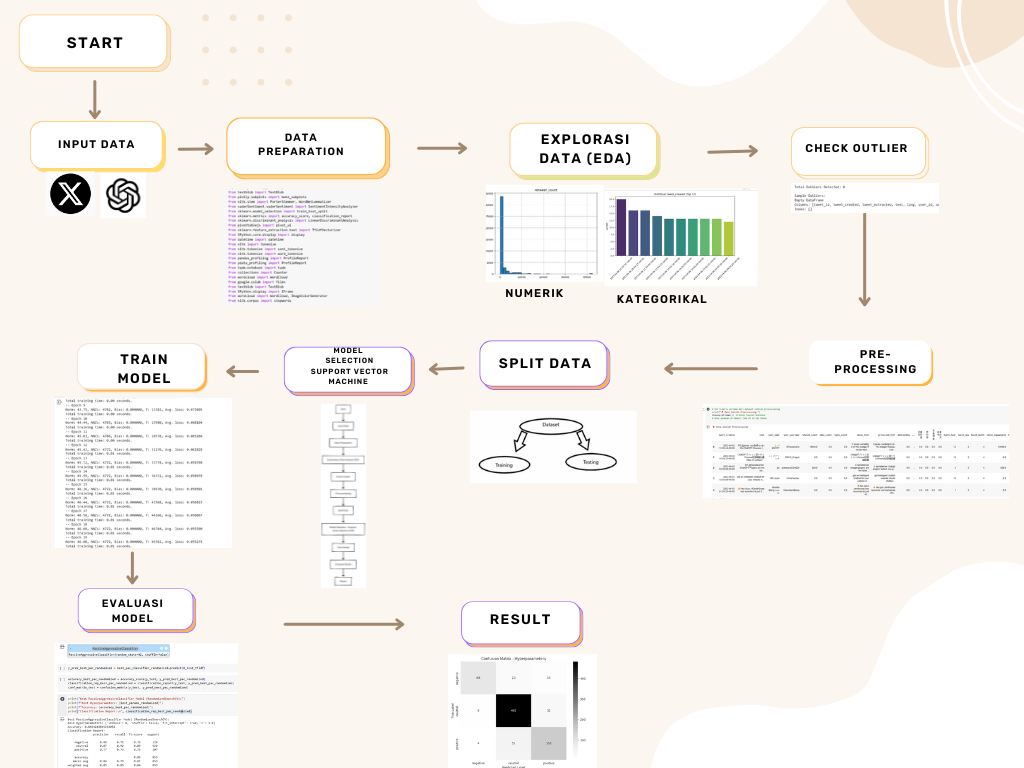

1. START
Proses dimulai dari tahap awal pemrosesan data.

2. INPUT DATA
Data dimasukkan ke dalam sistem, kemungkinan berasal dari platform seperti X (Twitter) atau OpenAI (berdasarkan ikon yang terlihat).

3. DATA PREPARATION
Menyiapkan Data dengan memasukkan Library

4. EXPLORASI DATA (EDA - Exploratory Data Analysis)
Data dianalisis untuk memahami pola, tren, dan distribusinya.

Numerik: Analisis variabel numerik, seperti distribusi nilai.
Kategorikal: Analisis variabel kategori, seperti jumlah kemunculan tiap kategori.

5. CHECK OUTLIER
Outlier dalam dataset diperiksa untuk memastikan apakah perlu dihapus atau ditangani dengan teknik tertentu.

6. PRE-PROCESSING
Data dibersihkan dan diproses agar siap digunakan untuk pelatihan model. Proses ini mencakup:

Normalisasi data
Feature Engineering

7. SPLIT DATA
Dataset dibagi menjadi training set dan test set, untuk memastikan model dapat belajar dari data latih dan diuji dengan data yang belum pernah dilihat sebelumnya.

8. MODEL SELECTION (Passive Aggressive Classifier)
Model Passive Aggressive Classifier dipilih sebagai algoritma yang digunakan untuk pelatihan.

9. TRAIN MODEL
Model dilatih menggunakan data training. Proses ini melibatkan optimasi bobot dan parameter model agar bisa mengenali pola dalam data.

10. EVALUASI MODEL
Setelah pelatihan, model diuji dengan data testing untuk melihat performanya. Evaluasi ini biasanya menggunakan metrik seperti akurasi, precision, recall, dan confusion matrix.

11. RESULT
Hasil akhir ditampilkan, biasanya dalam bentuk visualisasi seperti confusion matrix untuk melihat performa model dalam mengklasifikasikan data dengan benar.



#ARSITEKTUR MODEL

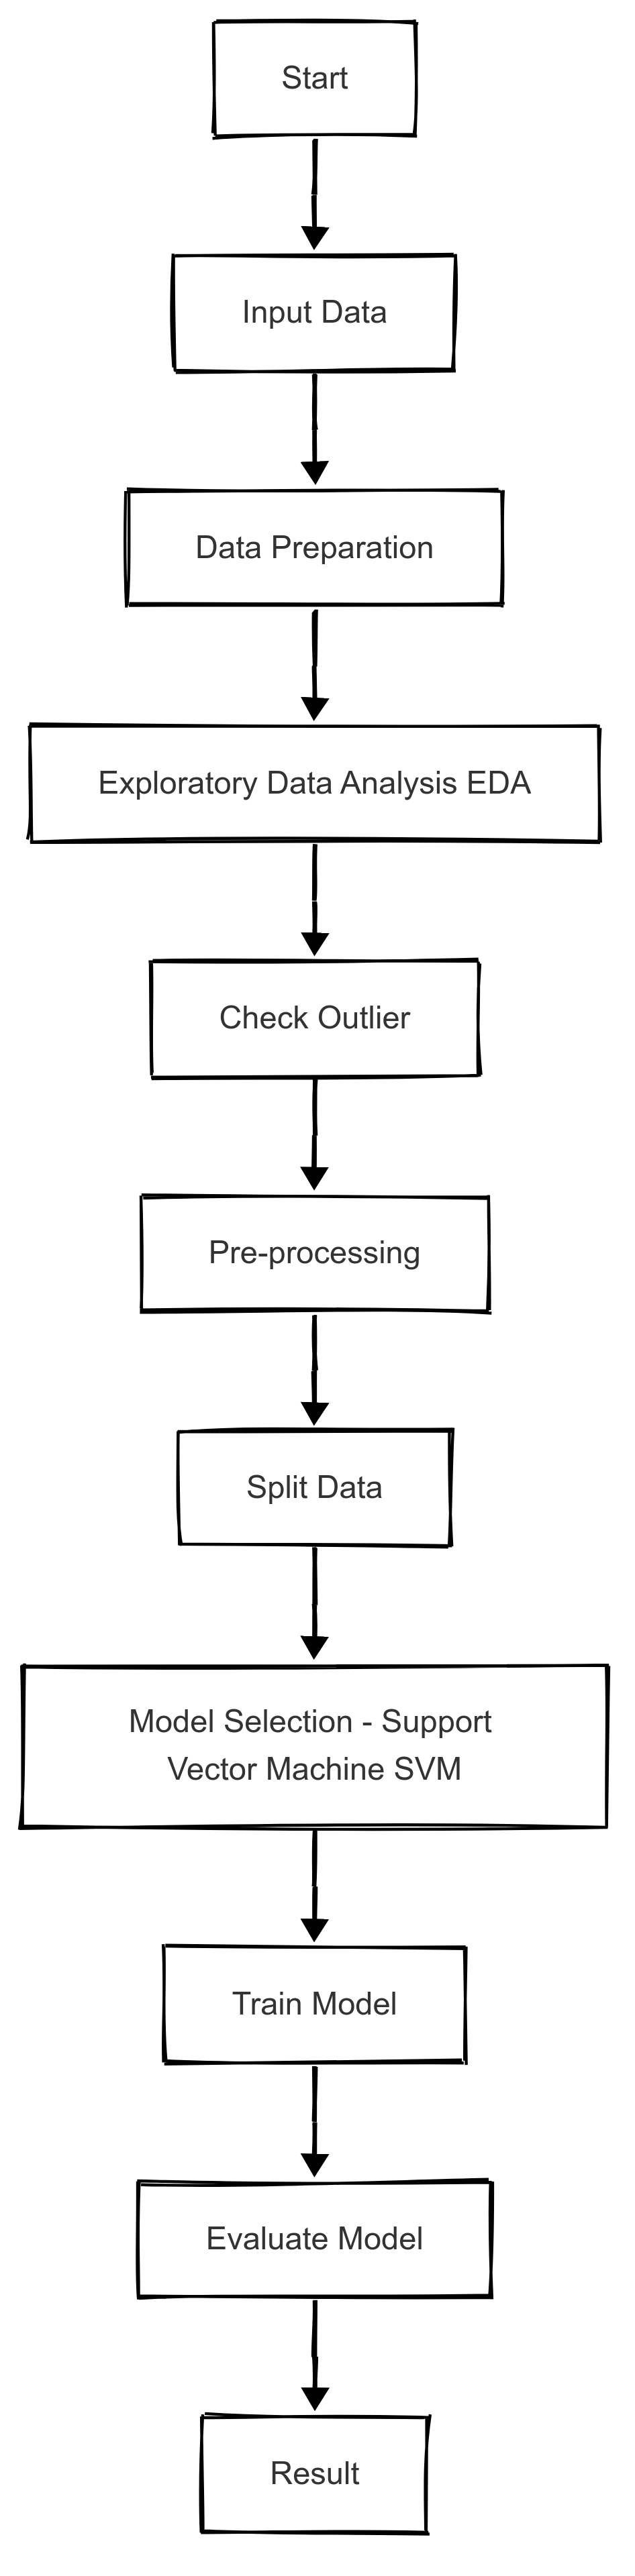

1. Mulai
Proses dimulai dengan langkah awal sebelum melakukan pemrosesan data dan pelatihan model.

2. Load Dataset
Dataset dimuat ke dalam sistem untuk diproses lebih lanjut.

3. Preprocessing Data
Data yang telah dimuat dibersihkan dan diproses agar siap digunakan untuk pelatihan model. Proses ini bisa mencakup:
- Menghilangkan data duplikat atau kosong
- Normalisasi teks
- Tokenisasi dan stemming (jika data berupa teks)
4. Split Data Train & Test
Dataset dibagi menjadi training set (data untuk melatih model) dan test set (data untuk menguji model).

5. Feature Extraction dengan TF-IDF
Mengubah teks menjadi representasi numerik menggunakan TF-IDF (Term Frequency - Inverse Document Frequency) agar dapat diproses oleh algoritma machine learning.

6. Train Model (PassiveAggressiveClassifier)
Model PassiveAggressiveClassifier dilatih menggunakan data hasil ekstraksi fitur. Model ini sering digunakan untuk klasifikasi teks, terutama dalam deteksi berita palsu (fake news detection).

7. Evaluasi Model
Setelah pelatihan, model diuji menggunakan test set untuk menilai kinerjanya.

8. Akurasi Bagus?
Jika akurasi model sudah cukup baik, langkah selanjutnya adalah penyimpanan model. Jika belum, dilakukan optimasi.

9. Optimasi?
- Jika model perlu ditingkatkan, dilakukan Hyperparameter Tuning untuk mencari kombinasi parameter terbaik agar meningkatkan performa model. Setelah itu, model dilatih kembali.
- Jika model tidak memerlukan optimasi lebih lanjut, langsung ke tahap berikutnya.

10. Simpan Model
Model yang telah dilatih dan dievaluasi disimpan agar bisa digunakan untuk prediksi di masa depan.

11. Selesai
Proses selesai dan model siap digunakan.

#FLOWCHART KERJA SETELAH DI REVISI

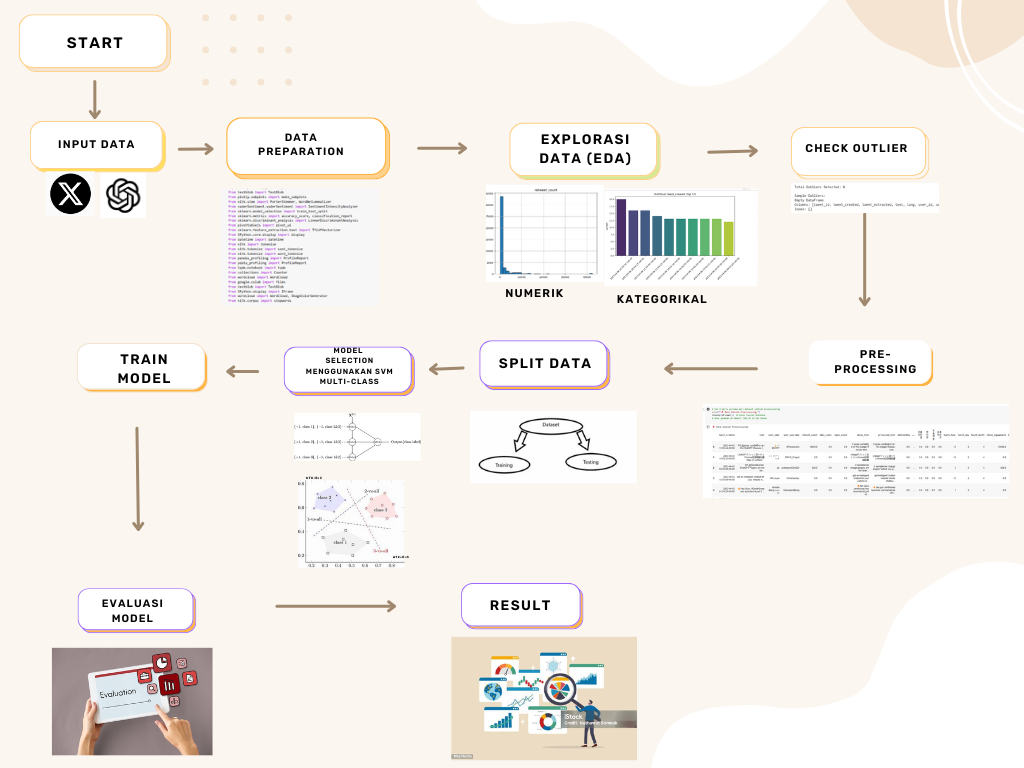

1. START
Proses dimulai dengan pengumpulan data, data di dapatkan dari kaggle.

2. INPUT DATA
Data dikumpulkan dari sumber tertentu, kemungkinan dari platform seperti Twitter (X) dan model AI (ChatGPT).

3. DATA PREPARATION
Menginstall  dan Memasukkan LIbrary yang di perlukan

4. EXPLORASI DATA (EDA)
Data dianalisis secara eksploratif untuk memahami distribusinya. Ini mencakup analisis fitur numerik dan kategori menggunakan visualisasi data.

5. CHECK OUTLIER
Periksa outlier yang ada di data

6. PRE-PROCESSING
Proses persiapan lebih lanjut dilakukan, seperti penghapusan stopwords, stemming, atau lemmatization.

7. SPLIT DATA
Data dibagi menjadi data latih (training) dan data uji (testing) untuk keperluan pembelajaran model.

8. MODEL SELECTION MENGGUNAKAN SVM MULTI-CLASS
Model Support Vector Machine (SVM) dengan pendekatan multi-class dipilih dan dikonfigurasi untuk menangani klasifikasi sentimen.

9. TRAIN MODEL
Model dilatih menggunakan data yang telah diproses sebelumnya.

10. EVALUASI MODEL
Performa model diuji menggunakan metrik evaluasi seperti akurasi, precision, recall, dan F1-score.

11. RESULT
Hasil akhir ditampilkan dalam bentuk visualisasi atau laporan.

# KOMPONEN ARSITEKTUR SUPPORT VECTOR MACHINE (SVM) MULTICLASS One-vs-All (OvA)



Dalam SVM Multiclass dengan pendekatan One-vs-All (OvA), beberapa komponen utama bekerja untuk mengklasifikasikan data ke dalam lebih dari dua kelas. Berikut adalah komponen-komponen utama yang terlibat:

1. Input Data (Fitur Ekstraksi dari Dataset)
Data yang digunakan: dalam analisis sentimen, data input biasanya berupa teks yang telah diproses menjadi fitur numerik, misalnya TF-IDF, Word2Vec, atau embeddings lainnya.
Dimensi tinggi: Data teks memiliki banyak fitur, yang membuat SVM unggul dalam menangani dataset berdimensi tinggi.

2. Representasi Data dalam Bentuk Vektor
Setiap teks diubah menjadi vektor fitur agar bisa diproses oleh model.
Representasi ini dapat menggunakan Bag-of-Words (BoW), TF-IDF, atau word embeddings seperti Word2Vec, GloVe, atau BERT.

3. Model SVM One-vs-All (OvA) dengan Beberapa Klasifikasi Biner
Konsep One-vs-All:
Jika ada 𝑁 kelas (misalnya, 3: positif, netral, negatif), maka model akan membuat 𝑁 SVM terpisah.
Setiap SVM bertugas membedakan satu kelas tertentu (+1) dari gabungan kelas lainnya (-1).
Arsitektur Model OvA:
SVM 1: Membedakan kelas positif (+1) vs (netral + negatif) (-1)
SVM 2: Membedakan kelas netral (+1) vs (positif + negatif) (-1)
SVM 3: Membedakan kelas negatif (+1) vs (positif + netral) (-1)


4. Kernel Trick (Transformasi Non-Linier Jika Diperlukan)
Jika data tidak bisa dipisahkan secara linear, maka kernel trick digunakan untuk mengubah data ke dalam dimensi yang lebih tinggi agar bisa dipisahkan dengan lebih baik.

Jenis kernel yang sering digunakan dalam SVM:
- Linear Kernel → Untuk data yang dapat dipisahkan dengan garis lurus.
- Polynomial Kernel → Untuk hubungan lebih kompleks.
- Radial Basis Function (RBF) Kernel → Untuk pemetaan non-linear ke dimensi tinggi.

5. Hyperplane dan Support Vectors
Hyperplane: Garis atau bidang yang memisahkan data dari kelas berbeda.
Support Vectors: Titik data yang paling dekat dengan hyperplane dan menentukan posisi optimal hyperplane.

6. Fungsi Maksimalisasi Margin
SVM mencari hyperplane terbaik dengan margin terbesar antara dua kelas.
Ini membuat model lebih tahan terhadap overfitting dan bekerja dengan baik pada data baru.
7. Penggabungan Keputusan dengan Metode Argmax
Setelah setiap SVM menghasilkan probabilitas atau skor untuk setiap kelas, sistem akan memilih kelas dengan skor tertinggi sebagai hasil akhir.
Contoh :
SVM 1 → 0.8 (positif)
SVM 2 → 0.2 (netral)
SVM 3 → 0.4 (negatif)
Argmax memilih kelas "positif" sebagai output.

8. Evaluasi Model
Setelah pelatihan, model diuji menggunakan metrik evaluasi seperti:
- Akurasi → Seberapa sering prediksi model benar.
- Precision, Recall, F1-Score → Mengukur performa klasifikasi setiap kelas.
- Confusion Matrix → Untuk melihat kesalahan klasifikasi antar kelas.



#ARSITEKTUR MODEL SETELAH DI REVISI

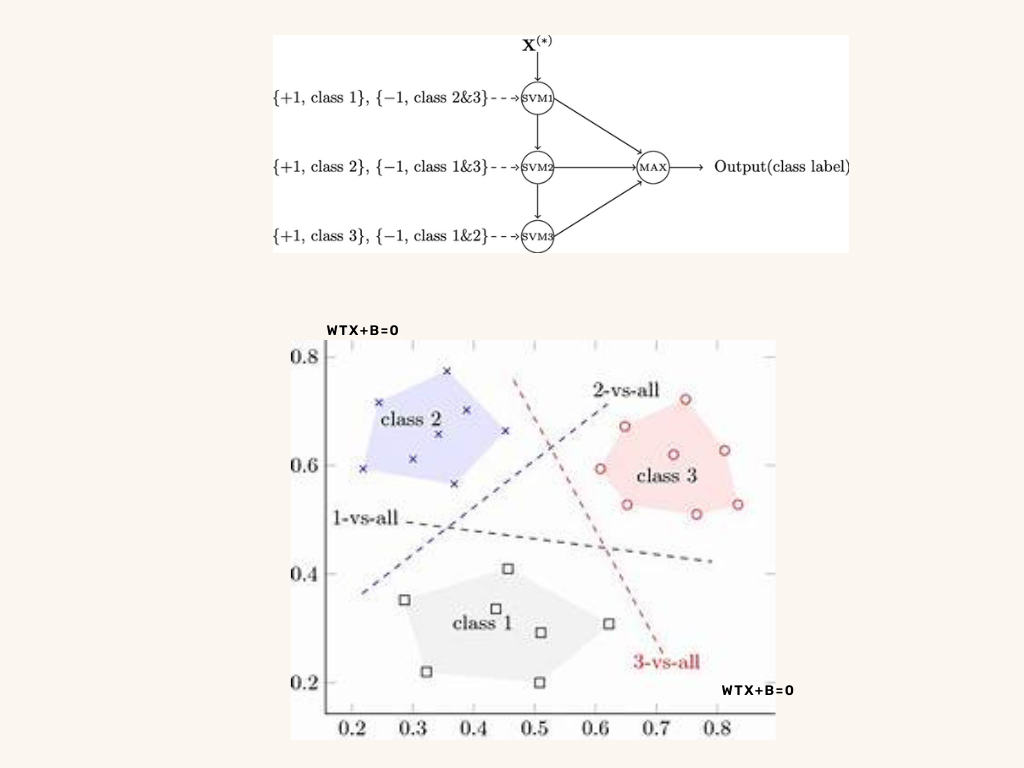

#Penjelasan Penggunaan Arsitektur SVM Only VS All dalam Klasifikasi Sentiment

 Bagaimana SVM One-vs-All (OvA) Bekerja untuk Analisis Sentimen?
Kamu sedang melakukan klasifikasi sentimen, di mana kamu ingin tahu apakah sebuah teks itu positif, negatif, atau netral.

Karena SVM pada dasarnya hanya bisa menangani dua kelas (biner), kita perlu cara untuk membuatnya bisa bekerja dengan tiga kelas. Nah, di sinilah pendekatan One-vs-All (OvA) digunakan!

 kita buat tiga model SVM yang masing-masing hanya fokus pada satu kelas dan menganggap dua kelas lainnya sebagai "lawan".

Misalnya:

- SVM1: Apakah teks ini positif atau bukan?
- SVM2: Apakah teks ini negatif atau bukan?
- SVM3: Apakah teks ini netral atau bukan?

Gambar Kedua (Plot Pembagian Wilayah Kelas oleh SVM)
Gambar ini menunjukkan bagaimana ruang fitur dipetakan oleh model SVM untuk memisahkan positif, negatif, dan netral.

Garis-garis pemisah (hyperplane) membagi area menjadi tiga wilayah:

- Wilayah putih untuk sentimen positif.
-  Wilayah biru untuk sentimen negatif.
- Wilayah merah untuk sentimen netral.

Setiap titik adalah teks yang dianalisis, dan posisi titik menentukan hasilnya berdasarkan garis pemisah terdekat.

# Training Model

## Split Data


In [ ]:
X = df['processed_text'].values
y = df['sentiment_label'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Membagi dataset menjadi data pelatihan (X_train, y_train) dan data pengujian (X_test, y_test) menggunakan fungsi train_test_split dari scikit-learn. Variabel X berisi teks yang telah diproses (processed_text), sedangkan y berisi label sentimen yang telah dikategorikan (sentiment_label). Pembagian dilakukan dengan rasio 80:20, di mana 80% data digunakan untuk melatih model dan 20% untuk menguji model, dengan random_state=42 untuk memastikan hasil pembagian tetap sama setiap kali dijalankan.


##TF-IDF Vectorizer

In [ ]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

##One-vs-All SVM Model

In [ ]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
svm_ova = OneVsRestClassifier(SVC(kernel='linear', random_state=42))
svm_ova.fit(X_train_tfidf, y_train)


Melatih model Support Vector Machine (SVM) dengan pendekatan One-vs-Rest (OvA) untuk klasifikasi multi-kelas, di mana setiap kelas dibandingkan dengan semua kelas lainnya secara terpisah. Model menggunakan SVC dengan kernel linear, yang cocok untuk data yang dapat dipisahkan secara linier, serta random_state=42 untuk memastikan hasil yang konsisten. Proses fit(X_train_tfidf, y_train) melatih model dengan data fitur yang telah diubah menggunakan TF-IDF serta label yang telah dienkode, sehingga model dapat mengenali pola dalam teks dan mengklasifikasikannya ke dalam kategori sentimen, seperti positif, negatif, atau netral.

##Model Prediksi label

In [ ]:
y_pred_svm = svm_ova.predict(X_test_tfidf)

Membuat prediksi terhadap data uji (X_test_tfidf) menggunakan model SVM One-vs-Rest (OvA) yang telah dilatih sebelumnya. Model ini akan menganalisis setiap sampel dalam X_test_tfidf dan menentukan label sentimen yang paling sesuai berdasarkan pola yang telah dipelajari dari data latih. Hasil prediksi tersebut disimpan dalam y_pred_svm, yang berisi label kategori sentimen (misalnya positif, negatif, atau netral) untuk setiap sampel dalam data uji.

##Evaluasi Model


In [ ]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
classification_rep_svm = classification_report(y_test, y_pred_svm)

print("Support Vector Machine One-vs-All Results:")
print(f"Accuracy: {accuracy_svm}")
print("Classification Report:\n", classification_rep_svm)

Akurasi Keseluruhan : 0.89975
Artinya, sekitar 90% dari seluruh prediksi model adalah benar.

🔹 Kelas 0 (Negatif)
Precision: 0.91
→ Dari seluruh prediksi yang dikatakan negatif, 91% benar-benar negatif. Ini berarti model cukup yakin saat memprediksi kelas ini.

Recall: 0.66
→ Hanya 66% dari semua data negatif yang berhasil terdeteksi. Masih ada cukup banyak yang meleset (false negative).

F1-score: 0.76
→ Kombinasi precision dan recall menunjukkan bahwa model kurang optimal dalam menangkap tweet negatif secara konsisten.

🔹 Kelas 1 (Netral)
Precision: 0.90

Recall: 0.97

F1-score: 0.94

→ Model sangat baik dalam mengenali tweet netral, dengan sangat sedikit kesalahan. Performa kuat ini wajar karena kelas ini memiliki jumlah data terbesar (2540), sehingga model cenderung lebih optimal dalam mengenalinya.

🔹 Kelas 2 (Positif)
Precision: 0.89

Recall: 0.82

F1-score: 0.85

→ Model bekerja cukup stabil dan seimbang untuk kelas positif, meskipun recall sedikit lebih rendah dibanding precision. Ini menunjukkan ada beberapa tweet positif yang gagal dikenali.

 Rata-rata Metrik:
1. Macro Avg (rata-rata per kelas tanpa mempertimbangkan jumlah data):

Precision: 0.90

Recall: 0.82

F1-score: 0.85
→ Cerminan rata-rata kinerja model secara umum di tiap kelas, menunjukkan bahwa recall masih bisa ditingkatkan terutama di kelas minoritas.

2. Weighted Avg (berat berdasarkan jumlah data di tiap kelas):

Precision: 0.90

Recall: 0.90

F1-score: 0.90
→ Ini menunjukkan performa keseluruhan stabil dan kuat, karena kelas netral (mayoritas) sangat mendominasi dan diidentifikasi dengan sangat baik.



##Confusion Matrix

In [ ]:
# Import the confusion_matrix function
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='pink', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for SVM OvA')
plt.show()

 Baris 1: Tweet dengan label asli negatif
271 tweet berhasil diklasifikasikan dengan benar sebagai negatif (✅)

93 tweet salah diklasifikasikan sebagai netral (❌)

49 tweet salah diklasifikasikan sebagai positif (❌)

Artinya, dari semua tweet yang benar-benar bernada negatif, sebagian besar terklasifikasi dengan tepat, meskipun masih cukup banyak yang keliru dianggap netral.

🔹 Baris 2: Tweet dengan label asli netral
2.469 tweet diklasifikasikan dengan benar sebagai netral (✅)

15 tweet salah diklasifikasikan sebagai negatif (❌)

56 tweet salah diklasifikasikan sebagai positif (❌)

Tweet dengan sentimen netral sebagian besar dikenali dengan sangat baik oleh model. Kesalahan klasifikasi ke kelas lain relatif kecil.

🔹 Baris 3: Tweet dengan label asli positif
859 tweet berhasil diklasifikasikan dengan benar sebagai positif (✅)

176 tweet salah diklasifikasikan sebagai netral (❌)

12 tweet salah diklasifikasikan sebagai negatif (❌)

Untuk tweet yang bernada positif, sebagian besar diklasifikasikan dengan benar. Namun, ada kecenderungan model menganggap sebagian tweet positif sebagai netral.

kurva ROC (Receiver Operating Characteristic) untuk model SVM dengan pendekatan One-vs-Rest (OvA) dalam klasifikasi sentimen multi-kelas (negatif, netral, positif). Setiap garis mewakili performa model dalam membedakan satu kelas terhadap dua kelas lainnya, dengan nilai AUC (Area Under the Curve) digunakan sebagai indikator akurasi. Model menunjukkan performa yang sangat baik dalam membedakan sentimen netral dan positif, masing-masing dengan AUC sebesar 0.95, sedangkan untuk sentimen negatif performanya cukup baik dengan AUC sebesar 0.89. Semakin tinggi nilai AUC, semakin baik model dalam mengklasifikasikan kelas tersebut, sehingga secara keseluruhan model SVM OvA ini efektif dalam mendeteksi pola sentimen pada data teks.

#HYPERPARAMETER TUNNING

#Tuning SVM dengan Kernel RBF

In [ ]:
from sklearn.model_selection import GridSearchCV
# Definisikan parameter grid untuk SVM RBF
param_grid = {
    'estimator__C': [1, 10],
    'estimator__gamma': [0.01, 0.1]
}


Melakukan tuning hyperparameter untuk model Support Vector Machine (SVM) dengan kernel RBF menggunakan GridSearchCV dari library scikit-learn. Parameter yang di-tuning adalah C dan gamma, di mana C mengontrol trade-off antara kesalahan klasifikasi dan margin decision boundary, sedangkan gamma menentukan seberapa jauh pengaruh satu data terhadap model. Parameter grid yang digunakan adalah C dengan nilai [1, 10] dan gamma dengan nilai [0.01, 0.1]. Penulisan estimator__C dan estimator__gamma menunjukkan bahwa parameter ini mungkin digunakan dalam pipeline atau dalam konteks model ensemble.

In [ ]:
# Inisialisasi model dasar
base_svm_rbf = OneVsRestClassifier(SVC(kernel='rbf', random_state=42))

# GridSearchCV
grid_search = GridSearchCV(base_svm_rbf, param_grid, cv=3, scoring='accuracy', verbose=1, n_jobs=-1)

# Fit model ke data training
grid_search.fit(X_train_tfidf, y_train)

# Cetak parameter terbaik
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validated Accuracy:", grid_search.best_score_)

Model dasar yang digunakan adalah kombinasi dari OneVsRestClassifier dengan SVC ber-kernel RBF, yang diinisialisasi dengan random_state=42 untuk memastikan hasil yang konsisten. Selanjutnya, dilakukan pencarian hyperparameter terbaik menggunakan GridSearchCV, dengan parameter grid yang telah didefinisikan sebelumnya, menggunakan 3-fold cross-validation (cv=3) dan evaluasi berdasarkan skor akurasi. Proses fitting model dilakukan pada data training X_train_tfidf dan y_train, di mana verbose=1 digunakan untuk menampilkan progres training dan n_jobs=-1 agar seluruh CPU core

digunakan untuk mempercepat proses. Output menunjukkan bahwa GridSearchCV mencoba 4 kombinasi parameter dengan total 12 fitting (3 fold × 4 kombinasi).

Pencetakan hasil dari proses GridSearchCV untuk menemukan kombinasi parameter terbaik pada model SVM. Dengan menggunakan atribut best_params_, diperoleh bahwa kombinasi terbaik adalah C=10 dan gamma=0.1, yang menghasilkan akurasi cross-validation terbaik sebesar 0.8917. Hasil ini menunjukkan bahwa model dengan parameter tersebut memiliki performa paling optimal di antara semua kombinasi parameter yang dicoba dalam grid search.










In [ ]:
# Prediksi menggunakan model terbaik
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_tfidf)

# Evaluasi
accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = classification_report(y_test, y_pred_best)

# Tampilkan hasil
print("\nEvaluasi Model Terbaik (SVM RBF + GridSearchCV):")
print(f"Accuracy: {accuracy_best}")
print("Classification Report:\n", report_best)

Akurasi: 0.90475

1. Kelas 0:
Precision: 0.90
→ Prediksi positif untuk kelas ini cukup akurat.

Recall: 0.68
→ Model sering gagal mendeteksi kelas ini, menunjukkan banyak false negatives.

F1-score: 0.78
→ Model kurang seimbang dalam mengenali kelas ini.

2. Kelas 1:
Precision: 0.91

Recall: 0.97

F1-score: 0.94
→ Performa sangat baik di semua metrik. Hal ini wajar karena kelas ini memiliki jumlah data paling besar (support = 2540), sehingga model lebih "terlatih" pada kelas ini.

3. Kelas 2:
Precision: 0.89

Recall: 0.83

F1-score: 0.86
→ Kinerja model cukup seimbang pada kelas ini, menunjukkan performa yang solid.

Rata-rata Metrik:
1. Macro Avg:
Menghitung rata-rata tiap metrik tanpa memperhatikan proporsi data tiap kelas.

Precision: 0.90

Recall: 0.83

F1-score: 0.86

2. Weighted Avg:
Rata-rata metrik dengan mempertimbangkan jumlah data tiap kelas.
Ini memberikan gambaran yang lebih representatif secara keseluruhan.

Precision: 0.90

Recall: 0.90

F1-score: 0.90

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Hitung confusion matrix
cm_best = confusion_matrix(y_test, y_pred_best)

# Label kelas (disesuaikan dengan klasifikasimu)
labels = ["negative", "neutral", "positive"]

# Visualisasikan dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="rocket", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix for Best Model (SVM RBF + GridSearchCV)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


- Baris 1: Tweet yang sebenarnya negatif
282 diprediksi benar sebagai negatif ✅

84 diprediksi salah sebagai netral ❌

47 diprediksi salah sebagai positif ❌

 Akurasi kelas negatif cukup baik, namun masih terdapat kesalahan prediksi ke kelas netral dan positif, menunjukkan bahwa beberapa tweet negatif mungkin memiliki nada yang tidak terlalu ekstrem atau ambigu secara sentimen.



- Baris 2: Tweet yang sebenarnya netral
2468 diprediksi benar sebagai netral ✅

16 diprediksi salah sebagai negatif ❌

56 diprediksi salah sebagai positif ❌

Kelas netral memiliki performa terbaik, dengan tingkat prediksi benar yang sangat tinggi. Hal ini menunjukkan bahwa model cukup andal dalam mengenali tweet-tweet dengan nuansa netral atau informatif.




- Baris 3: Tweet yang sebenarnya positif
869 diprediksi benar sebagai positif ✅

163 diprediksi salah sebagai netral ❌

15 diprediksi salah sebagai negatif ❌

Untuk kelas positif, model cenderung cukup sering keliru memprediksi sebagai netral, yang bisa jadi disebabkan oleh ekspresi positif yang kurang eksplisit atau karena adanya kata-kata umum yang juga sering muncul dalam tweet netral.



1. Kelas: Negative
True Positive (TP): 282
→ Model benar memprediksi data negative sebagai negative.

False Positive (FP):

Neutral dikira negative: 16

Positive dikira negative: 15
➤ Total FP = 31

False Negative (FN):

Negative dikira neutral: 84

Negative dikira positive: 47
➤ Total FN = 131

True Negative (TN):
Semua data non-negative yang diprediksi bukan negative:

Neutral → Neutral: 2468

Neutral → Positive: 56

Positive → Neutral: 163

Positive → Positive: 869
➤ TN = 3556

2. Kelas: Neutral
True Positive (TP): 2468
→ Model benar memprediksi data neutral sebagai neutral.

False Positive (FP):

Negative → Neutral: 84

Positive → Neutral: 163
➤ Total FP = 247

False Negative (FN):

Neutral → Negative: 16

Neutral → Positive: 56
➤ Total FN = 72

True Negative (TN):
Semua data non-neutral yang diprediksi bukan neutral:

Negative → Negative: 282

Negative → Positive: 47

Positive → Negative: 15

Positive → Positive: 869
➤ TN = 1213

3. Kelas: Positive
True Positive (TP): 869
→ Model benar memprediksi data positive sebagai positive.

False Positive (FP):

Negative → Positive: 47

Neutral → Positive: 56
➤ Total FP = 103

False Negative (FN):

Positive → Negative: 15

Positive → Neutral: 163
➤ Total FN = 178

True Negative (TN):
Semua data non-positive yang diprediksi bukan positive:

Negative → Negative: 282

Negative → Neutral: 84

Neutral → Negative: 16

Neutral → Neutral: 2468
➤ TN = 2850



# Tuning SVM dengan POLI

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, classification_report
# Definisikan model dasar
base_model = OneVsRestClassifier(SVC(kernel='poly'))

# Grid kecil (lightweight)
param_grid = {
    'estimator__degree': [2, 3],           # Coba derajat polynomial 2 dan 3
    'estimator__C': [1, 10],               # C kecil dan sedang
    'estimator__gamma': ['scale'],         # Default setting saja
    'estimator__coef0': [0]                # Bias term default
}


tuning hyperparameter untuk model Support Vector Machine (SVM) dengan kernel polinomial menggunakan GridSearchCV, di mana model dasarnya adalah OneVsRestClassifier dengan SVC(kernel='poly'). Parameter grid yang didefinisikan mencakup degree (tingkat polinomial) dengan nilai 2 dan 3, C dengan nilai 1 dan 10 untuk mengatur kekuatan regularisasi, gamma menggunakan nilai default 'scale', serta coef0 diatur ke 0 untuk bias term default. Grid yang kecil ini dipilih agar proses pencarian lebih ringan dan cepat, sambil tetap mengeksplorasi kombinasi parameter yang relevan.

In [ ]:
# GridSearchCV
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=3,
    verbose=1,
    n_jobs=-1
)


# Fit ke data training
grid_search.fit(X_train_tfidf, y_train)




 Proses pencarian kombinasi hyperparameter terbaik untuk model SVM dengan kernel polinomial menggunakan GridSearchCV. Model base_model dan param_grid yang telah didefinisikan sebelumnya digunakan dalam GridSearchCV, dengan evaluasi akurasi (scoring='accuracy'), 3-fold cross-validation (cv=3), serta parallel processing (n_jobs=-1) untuk mempercepat training. Proses fitting dilakukan terhadap data training X_train_tfidf dan y_train, dan output menunjukkan bahwa terdapat 4 kombinasi parameter yang diuji, menghasilkan total 12 fitting karena setiap kombinasi diuji pada 3 fold cross-validation.

In [ ]:
# Gunakan model terbaik
best_model = grid_search.best_estimator_
y_pred_poly = best_model.predict(X_test_tfidf)

# Evaluasi
accuracy_poly = accuracy_score(y_test, y_pred_poly)
classification_rep_poly = classification_report(y_test, y_pred_poly)

print("SVM Polynomial Kernel - One-vs-Rest Results:")
print(f"Accuracy: {accuracy_poly}")
print("Classification Report:\n", classification_rep_poly)

# Tampilkan parameter terbaik
print("Best Parameters:", grid_search.best_params_)


SVM Polynomial Kernel – One-vs-Rest
Akurasi: 0.8845

1. Kelas 0 (Negative)
Precision: 0.97
→ Prediksi positif untuk kelas ini sangat akurat.

Recall: 0.62
→ Model sering gagal mendeteksi kelas ini dengan benar.

F1-score: 0.75
→ Meskipun precision tinggi, rendahnya recall menyebabkan f1-score menjadi cukup rendah, menunjukkan ketidakseimbangan dalam performa.

2. Kelas 1 (Neutral)
Precision: 0.87

Recall: 0.98

F1-score: 0.92
→ Performa sangat baik dan stabil di semua metrik.
Hal ini wajar karena jumlah data di kelas ini paling banyak (support = 2540), membuat model lebih "terbiasa" mengenalinya.

3. Kelas 2 (Positive)
Precision: 0.90

Recall: 0.89

F1-score: 0.89
→ Model bekerja cukup baik dengan keseimbangan antara precision dan recall yang tinggi.

Rata-rata Metrik
1. Macro Avg:
Menghitung rata-rata tiap metrik tanpa memperhatikan jumlah data per kelas.

Precision: 0.91

Recall: 0.79

F1-score: 0.85
→ Terlihat bahwa secara umum performa cukup baik, meskipun recall agak turun karena kelas 0.

2. Weighted Avg:
Menghitung rata-rata dengan mempertimbangkan jumlah data per kelas.

Precision: 0.89

Recall: 0.88

F1-score: 0.88
→ Lebih representatif secara keseluruhan, menunjukkan performa model secara umum tetap bagus.



In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Hitung confusion matrix
cm_poly = confusion_matrix(y_test, y_pred_poly)

# Label kelas (disesuaikan dengan dataset kamu)
labels = ["negative", "neutral", "positive"]

# Visualisasikan dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_poly, annot=True, fmt="d", cmap="rocket", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix for SVM Polynomial Kernel")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Baris 1: Tweet yang sebenarnya negatif
255 diprediksi benar sebagai negatif ✅

119 diprediksi salah sebagai netral ❌

39 diprediksi salah sebagai positif ❌

Model masih mengalami cukup banyak kesalahan dengan memprediksi tweet negatif sebagai netral, yang mengindikasikan kemungkinan kurangnya fitur yang dapat membedakan nada negatif yang halus dari netral.

Baris 2: Tweet yang sebenarnya netral
2479 diprediksi benar sebagai netral ✅

3 diprediksi salah sebagai negatif ❌

58 diprediksi salah sebagai positif ❌

Model sangat akurat dalam mengenali tweet netral, bahkan sedikit lebih baik dibandingkan model RBF sebelumnya (dengan hanya 3 salah prediksi sebagai negatif). Ini menunjukkan konsistensi tinggi dalam memetakan tweet informatif atau tanpa emosi.

Baris 3: Tweet yang sebenarnya positif
804 diprediksi benar sebagai positif ✅

237 diprediksi salah sebagai netral ❌

6 diprediksi salah sebagai negatif ❌

Kinerja terhadap tweet positif agak menurun dibandingkan model RBF. Tingginya jumlah prediksi ke kelas netral menunjukkan bahwa model kesulitan menangkap ekspresi positif, mungkin karena kata-kata pujian ringan masih mirip dengan bahasa netral.

1. Kelas: Negative
True Positive (TP): 255
→ Model berhasil memprediksi data negative sebagai negative.

False Positive (FP):

Neutral dikira negative: 3

Positive dikira negative: 6
➤ Total FP = 3 + 6 = 9

False Negative (FN):

Negative dikira neutral: 119

Negative dikira positive: 39
➤ Total FN = 119 + 39 = 158

True Negative (TN):
Semua data selain kelas negative yang tidak diprediksi sebagai negative:

Neutral → Neutral = 2479

Neutral → Positive = 58

Positive → Neutral = 237

Positive → Positive = 804
➤ TN = 2479 + 58 + 237 + 804 = 3578

2. Kelas: Neutral
True Positive (TP): 2479
→ Model berhasil memprediksi data neutral sebagai neutral.

False Positive (FP):

Negative → Neutral: 119

Positive → Neutral: 237
➤ Total FP = 119 + 237 = 356

False Negative (FN):

Neutral dikira negative: 3

Neutral dikira positive: 58
➤ Total FN = 3 + 58 = 61

True Negative (TN):

Negative → Negative = 255

Negative → Positive = 39

Positive → Negative = 6

Positive → Positive = 804
➤ TN = 255 + 39 + 6 + 804 = 1104

3. Kelas: Positive
True Positive (TP): 804
→ Model berhasil memprediksi data positive sebagai positive.

False Positive (FP):

Negative → Positive: 39

Neutral → Positive: 58
➤ Total FP = 39 + 58 = 97

False Negative (FN):

Positive dikira negative: 6

Positive dikira neutral: 237
➤ Total FN = 6 + 237 = 243

True Negative (TN):

Negative → Negative = 255

Negative → Neutral = 119

Neutral → Negative = 3

Neutral → Neutral = 2479
➤ TN = 255 + 119 + 3 + 2479 = 2856

#Tuning SVM dengan sigmoid kernel



In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.multiclass import OneVsRestClassifier

# Model dasar
base_model = OneVsRestClassifier(SVC(kernel='sigmoid'))

# Hyperparameter space (ringan & efisien)
param_dist = {
    'estimator__C': [0.1, 1, 10],
    'estimator__gamma': ['scale', 'auto'],
    'estimator__coef0': [0.0, 0.5, 1.0]
}


Tuning hyperparameter model SVM dengan kernel sigmoid menggunakan RandomizedSearchCV, yang lebih efisien dibandingkan GridSearchCV untuk ruang pencarian yang besar. Model dasar yang digunakan adalah OneVsRestClassifier dengan SVC(kernel='sigmoid'). Hyperparameter yang akan dituning meliputi C (nilai 0.1, 1, dan 10) untuk pengaturan regularisasi, gamma (pilihan 'scale' atau 'auto') untuk mengontrol jarak pengaruh data, serta coef0 (nilai 0.0, 0.5, dan 1.0) yang mempengaruhi bias di dalam fungsi kernel sigmoid. Pendekatan ini bertujuan menjaga tuning tetap ringan dan efisien.

In [ ]:
# RandomizedSearchCV
random_search = RandomizedSearchCV(
    base_model,
    param_distributions=param_dist,
    n_iter=5,                  # Bisa disesuaikan
    scoring='accuracy',
    cv=2,
    verbose=1,
    n_jobs=-1,
    random_state=99
)

# Fit model
random_search.fit(X_train_tfidf, y_train)

RandomizedSearchCV untuk melakukan tuning hyperparameter pada model SVM dengan kernel sigmoid. Dengan n_iter=5, RandomizedSearch akan mencoba 5 kombinasi parameter secara acak dari distribusi yang sudah didefinisikan sebelumnya, sehingga lebih cepat dibandingkan grid search. Evaluasi model dilakukan menggunakan 2-fold cross-validation (cv=2) dan pengukuran akurasi (scoring='accuracy'), dengan semua core prosesor digunakan (n_jobs=-1) untuk mempercepat proses. Model kemudian di-fit terhadap data X_train_tfidf dan y_train, dan hasilnya menunjukkan bahwa dari 5 kandidat parameter, dilakukan total 10 kali fitting untuk cross-validation.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Prediksi menggunakan model terbaik
best_model_sigmoid = random_search.best_estimator_
y_pred_sigmoid = best_model_sigmoid.predict(X_test_tfidf)

# Evaluasi
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
classification_rep_sigmoid = classification_report(y_test, y_pred_sigmoid)

print("Support Vector Machine (Sigmoid Kernel) - One-vs-All Results:")
print(f"Accuracy: {accuracy_sigmoid}")
print("Classification Report:\n", classification_rep_sigmoid)

# Tampilkan parameter terbaik
print("Best Parameters:", random_search.best_params_)


1. Kelas 0 (Negative)
Precision: 0.51
→ Hanya 51% dari prediksi kelas 0 yang benar-benar tepat.

Recall: 0.60
→ Model hanya menangkap 60% dari seluruh data kelas 0 yang sebenarnya.

F1-Score: 0.55
→ Gabungan antara precision dan recall yang cukup rendah, menunjukkan performa buruk untuk kelas ini.

-  Catatan: Model kesulitan dalam mengenali kelas ini, mungkin karena jumlah datanya paling sedikit (support = 413).

2. Kelas 1 (Neutral)
Precision: 0.87
→ Tingkat akurasi prediksi sangat baik.

Recall: 0.91
→ Hampir semua data kelas 1 berhasil dikenali oleh model.

F1-Score: 0.89
→ Kombinasi precision dan recall yang seimbang dan tinggi.

- Catatan: Performa terbaik di antara semua kelas. Wajar karena jumlah data paling besar (support = 2540).

3. Kelas 2 (Positive)
Precision: 0.79
→ Sebagian besar prediksi positif benar.

Recall: 0.64
→ Model gagal menangkap sekitar 36% dari data yang benar-benar positif.

F1-Score: 0.71
→ Kinerja cukup baik, meskipun recall bisa lebih ditingkatkan.

- Catatan: Masih ada potensi perbaikan, terutama dalam hal mengenali seluruh data positif.

Rata-rata Metrik
Macro Average:

Precision: 0.72

Recall: 0.71

F1-Score: 0.71
➤ Rata-rata dari semua kelas tanpa mempertimbangkan jumlah data. Nilainya moderat, mencerminkan ketidakseimbangan antar kelas.

Weighted Average:

Precision: 0.81

Recall: 0.81

F1-Score: 0.80
➤ Rata-rata yang mempertimbangkan proporsi jumlah data per kelas. Lebih representatif untuk performa keseluruhan.



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Buat confusion matrix
cm = confusion_matrix(y_test, y_pred_sigmoid)

# Label kelas
labels = ['negative', 'neutral', 'positive']

# Plot confusion matrix dengan seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for SVM Sigmoid Kernel')
plt.show()


- Baris 1: Tweet yang sebenarnya negatif
246 diprediksi benar sebagai negatif ✅

105 diprediksi salah sebagai netral ❌

62 diprediksi salah sebagai positif ❌

Model mengalami kesulitan membedakan sentimen negatif dari netral atau positif. Ini bisa jadi karena nada negatif yang kurang eksplisit atau mirip dengan bahasa netral, membuat model sering keliru mengenali konteks sebenarnya.

- Baris 2: Tweet yang sebenarnya netral
2305 diprediksi benar sebagai netral ✅

115 diprediksi salah sebagai negatif ❌

120 diprediksi salah sebagai positif ❌

Meskipun model masih dominan benar dalam mengenali tweet netral, terdapat lebih banyak kesalahan dibandingkan model Polynomial (2479 benar sebelumnya). Ini menunjukkan bahwa model Sigmoid kurang konsisten dalam menangkap nuansa netral, terutama ketika tweet mengandung sedikit opini.

- Baris 3: Tweet yang sebenarnya positif
670 diprediksi benar sebagai positif ✅

251 diprediksi salah sebagai netral ❌

126 diprediksi salah sebagai negatif ❌

Model cukup kesulitan dalam mengidentifikasi tweet positif. Sebagian besar kekeliruan berupa klasifikasi ke kelas netral, mengindikasikan bahwa ekspresi positif tidak cukup kuat untuk dibedakan secara konsisten. Hal ini umum jika model tidak cukup "peka" terhadap kata-kata positif ringan atau ambigu.



#BEST HYPERPARAMETER

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Define parameter grid untuk semua kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'poly','sigmoid']
}

# 2. Inisialisasi GridSearchCV
grid = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    refit=True,
    verbose=3,
    scoring='accuracy',
    cv=2,
    n_jobs=-1
)

# 3. Fit ke data training
grid.fit(X_train_tfidf, y_train)

# 4. Print best params dan score
print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Score:", grid.best_score_)

# 5. Evaluasi pada validation set (bisa pakai split sendiri, ini contoh jika tersedia X_val & y_val)
best_svm_classifier = grid.best_estimator_

# Misal validasi manual (bisa diskip jika langsung uji)
# y_val_pred = best_svm_classifier.predict(X_val)
# accuracy_val = accuracy_score(y_val, y_val_pred)
# print("\nValidation Accuracy:", accuracy_val)
# print(classification_report(y_val, y_val_pred))
# print(confusion_matrix(y_val, y_val_pred))

# 6. Evaluasi pada test set
y_pred_test = best_svm_classifier.predict(X_test_tfidf)
accuracy_test = accuracy_score(y_test, y_pred_test)
print("\nTest Accuracy:", accuracy_test)
print(classification_report(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))


1. Kelas 0 (Negative)
Precision: 0.95
→ Dari seluruh prediksi kelas 0, sebanyak 95% memang benar kelas 0.

Recall: 0.67
→ Model hanya mampu mendeteksi 67% dari seluruh data negative.

F1-Score: 0.79
→ Kombinasi precision tinggi dan recall rendah menunjukkan model cukup akurat namun kurang sensitif terhadap kelas ini.

- Catatan: Jumlah data sedikit (support = 413), mungkin menyebabkan model kurang optimal dalam mengenalinya.

2. Kelas 1 (Neutral)
Precision: 0.91
→ Akurasi prediksi sangat baik.

Recall: 0.97
→ Hampir semua data kelas 1 berhasil dikenali.

F1-Score: 0.94
→ Performa sangat baik dan seimbang.

- Catatan: Jumlah data paling banyak (support = 2540), sehingga model lebih terlatih untuk kelas ini.

3. Kelas 2 (Positive)
Precision: 0.88
→ Sebagian besar prediksi kelas 2 benar.

Recall: 0.85
→ Sebagian besar data positif berhasil dikenali.

F1-Score: 0.86
→ Model cukup konsisten dan akurat dalam mendeteksi kelas ini.

Rata-rata Metrik
1. Macro Average:

Precision: 0.91

Recall: 0.83

F1-Score: 0.86
➤ Rata-rata antar kelas tanpa memperhitungkan distribusi data.

2. Weighted Average:

Precision: 0.91

Recall: 0.91

F1-Score: 0.90
➤ Lebih mencerminkan performa keseluruhan karena mempertimbangkan jumlah data tiap kelas.



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Confusion matrix dari output yang kamu tunjukin
cm_rbf_manual = np.array([[278, 83, 52],
                          [8, 2464, 68],
                          [8, 154, 885]])

# Label kelas
labels = ["negative", "neutral", "positive"]

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rbf_manual, annot=True, fmt="d", cmap="rocket", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix Best Parameter")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



1. Kelas: Negative
True Positive (TP): 278
→ Model berhasil mengklasifikasikan 278 data negative dengan benar.

False Positive (FP):

Neutral dikira negative: 8

Positive dikira negative: 8
➤ Total FP = 16

False Negative (FN):

Negative dikira neutral: 83

Negative dikira positive: 52
➤ Total FN = 135

True Negative (TN):
Semua data yang bukan kelas negative dan juga tidak diprediksi sebagai negative:
➤ TN = 2464 (neutral → neutral) + 68 (neutral → positive) + 154 (positive → neutral) + 885 (positive → positive) = 3571

2. Kelas: Neutral
True Positive (TP): 2464
→ Model berhasil mengklasifikasikan 2464 data neutral dengan benar.

False Positive (FP):

Negative → Neutral: 83

Positive → Neutral: 154
➤ Total FP = 237

False Negative (FN):

Neutral → Negative: 8

Neutral → Positive: 68
➤ Total FN = 76

True Negative (TN):
➤ TN = 278 (negative → negative) + 52 (negative → positive) + 8 (positive → negative) + 885 (positive → positive) = 1223

3. Kelas: Positive
True Positive (TP): 885
→ Model berhasil mengklasifikasikan 885 data positive dengan benar.

False Positive (FP):

Negative → Positive: 52

Neutral → Positive: 68
➤ Total FP = 120

False Negative (FN):

Positive → Negative: 8

Positive → Neutral: 154
➤ Total FN = 162

True Negative (TN):
➤ TN = 278 (negative → negative) + 83 (negative → neutral) + 8 (neutral → negative) + 2464 (neutral → neutral) = 2833



#DECISION TREE

#ARSITEKTUR DECISION TREE

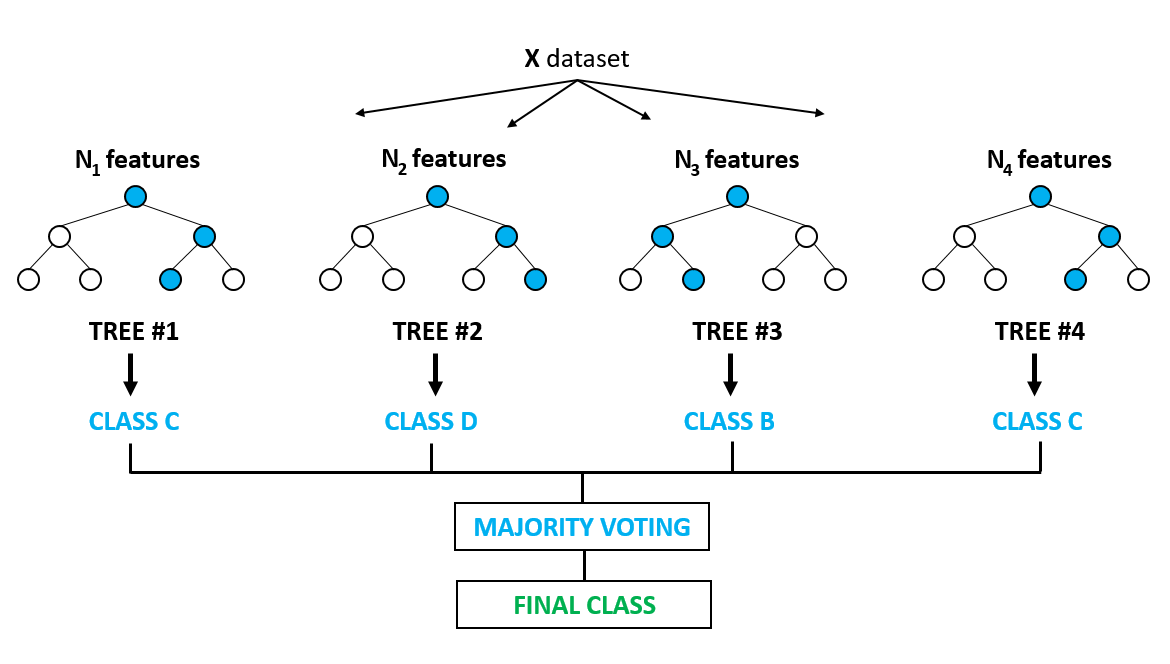





menggambarkan arsitektur dari metode ensemble berbasis decision tree, seperti Random Forest. Dataset awal (X) dibagi ke dalam beberapa subset fitur yang berbeda, yang kemudian digunakan untuk melatih beberapa pohon keputusan secara paralel. Setiap pohon (TREE #1 sampai TREE #4) dilatih menggunakan subset fitur yang unik (N₁, N₂, N₃, N₄), dan masing-masing menghasilkan prediksi kelasnya sendiri, misalnya Class C, D, B, dan C. Setelah semua pohon memberikan hasil prediksi, dilakukan proses majority voting, yaitu pengambilan suara terbanyak dari seluruh prediksi pohon. Hasil dari voting ini akan menentukan kelas akhir (Final Class) yang menjadi keputusan akhir model. Pendekatan ini membuat model lebih akurat dan tahan terhadap overfitting dibandingkan hanya menggunakan satu decision tree, karena menggabungkan kekuatan dari beberapa model sederhana menjadi satu model yang lebih kuat dan stabil.









In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Kombinasi Baru - Bukan dari 3 kombinasi sebelumnya
dt_new = DecisionTreeClassifier(criterion='entropy', max_depth=15, min_samples_leaf=4, random_state=42)
dt_new.fit(X_train_tfidf, y_train)
y_pred_new = dt_new.predict(X_test_tfidf)

# Evaluasi
acc_new = accuracy_score(y_test, y_pred_new)
report_new = classification_report(y_test, y_pred_new)

# Output
print("=== Decision Tree Classifier (New Parameters) ===")
print(f"Accuracy: {acc_new:.4f}")
print(report_new)


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Hitung confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_new)

# Label kelas (disesuaikan dengan output gambar: 0 = negative, 1 = neutral, 2 = positive)
labels = ["negative", "neutral", "positive"]

# Visualisasikan dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="rocket", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix for Decision Tree Classifier (New Parameters)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Kombinasi 1
dt1 = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt1.fit(X_train_tfidf, y_train)
y_pred1 = dt1.predict(X_test_tfidf)
acc1 = accuracy_score(y_test, y_pred1)
report1 = classification_report(y_test, y_pred1)

# Kombinasi 2
dt2 = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_split=5, random_state=42)
dt2.fit(X_train_tfidf, y_train)
y_pred2 = dt2.predict(X_test_tfidf)
acc2 = accuracy_score(y_test, y_pred2)
report2 = classification_report(y_test, y_pred2)

# Kombinasi 3
dt3 = DecisionTreeClassifier(criterion='gini', max_depth=None, min_samples_leaf=3, random_state=42)
dt3.fit(X_train_tfidf, y_train)
y_pred3 = dt3.predict(X_test_tfidf)
acc3 = accuracy_score(y_test, y_pred3)
report3 = classification_report(y_test, y_pred3)

# Tampilkan hasil
print("=== Decision Tree Classifier Results ===")
print(f"Parameter 1 (gini, max_depth=5)               - Accuracy: {acc1:.4f}")
print(report1)
print(f"Parameter 2 (entropy, max_depth=10, split=5)  - Accuracy: {acc2:.4f}")
print(report2)
print(f"Parameter 3 (gini, no max_depth, leaf=3)      - Accuracy: {acc3:.4f}")
print(report3)


1. Parameter 1: (criterion = gini, max_depth = 5)
Accuracy: 0.6843

Kelas 0 (Negative)

Precision: 1.00 → Semua prediksi sebagai kelas 0 benar.

Recall: 0.33 → Hanya 33% data negative yang berhasil dikenali.

F1-Score: 0.50 → Rendah karena recall sangat kecil.

Kelas 1 (Neutral)

Precision: 0.70

Recall: 0.84

F1-Score: 0.76 → Cukup baik karena seimbang.

Kelas 2 (Positive)

Precision: 0.60

Recall: 0.32 → Banyak data positif tidak terdeteksi.

F1-Score: 0.41 → Kurang baik.

Rata-Rata Metrik:

Macro Avg: Precision = 0.76, Recall = 0.43, F1-Score = 0.56

Weighted Avg: Precision = 0.70, Recall = 0.68, F1-Score = 0.62

2. Parameter 2: (criterion = entropy, max_depth = None, min_samples_split = 5)
Accuracy: 0.7070

Kelas 0 (Negative)

Precision: 0.87

Recall: 0.17 → Model hanya mengenali sedikit data negative.

F1-Score: 0.28

Kelas 1 (Neutral)

Precision: 0.71

Recall: 0.95

F1-Score: 0.81 → Sangat baik untuk kelas ini.

Kelas 2 (Positive)

Precision: 0.65

Recall: 0.34

F1-Score: 0.45

Rata-Rata Metrik:

Macro Avg: Precision = 0.74, Recall = 0.48, F1-Score = 0.51

Weighted Avg: Precision = 0.71, Recall = 0.71, F1-Score = 0.66

3. Parameter 3: (criterion = gini, no max_depth, min_samples_leaf = 3)
Accuracy: 0.8235

Kelas 0 (Negative)

Precision: 0.65

Recall: 0.63

F1-Score: 0.64 → Seimbang, meskipun masih bisa ditingkatkan.

Kelas 1 (Neutral)

Precision: 0.86

Recall: 0.91

F1-Score: 0.89 → Sangat baik, model mengenali dengan akurat.

Kelas 2 (Positive)

Precision: 0.79

Recall: 0.69

F1-Score: 0.73 → Lumayan stabil.

Rata-Rata Metrik:

Macro Avg: Precision = 0.77, Recall = 0.74, F1-Score = 0.75

Weighted Avg: Precision = 0.82, Recall = 0.82, F1-Score = 0.82

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Misal hasil prediksi dari tiga parameter:
# y_pred1, y_pred2, y_pred3
# dan label asli
# y_test

# Buat confusion matrix
cm1 = confusion_matrix(y_test, y_pred1)
cm2 = confusion_matrix(y_test, y_pred2)
cm3 = confusion_matrix(y_test, y_pred3)

# Label kelas
labels = ['neg', 'neu', 'pos']

# Plot 3 confusion matrix
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axs[0])
axs[0].set_title('Confusion Matrix - Param 1')
axs[0].set_xlabel('Predicted')
axs[0].set_ylabel('Actual')

sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axs[1])
axs[1].set_title('Confusion Matrix - Param 2')
axs[1].set_xlabel('Predicted')
axs[1].set_ylabel('Actual')

sns.heatmap(cm3, annot=True, fmt='d', cmap='Oranges', xticklabels=labels, yticklabels=labels, ax=axs[2])
axs[2].set_title('Confusion Matrix - Param 3')
axs[2].set_xlabel('Predicted')
axs[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()


1. Confusion Matrix - Param 1

- Baris 1: Tweet yang sebenarnya negatif
✅ 12 diprediksi benar sebagai negatif
❌ 324 diprediksi salah sebagai netral
❌ 77 diprediksi salah sebagai positif

Model sangat kesulitan mengenali sentimen negatif. Sebagian besar tweet negatif diklasifikasikan sebagai netral, menunjukkan bahwa model tidak cukup peka terhadap ekspresi negatif yang mungkin tersirat atau kurang eksplisit.

- Baris 2: Tweet yang sebenarnya netral
✅ 2394 diprediksi benar sebagai netral
❌ 0 diprediksi salah sebagai negatif
❌ 146 diprediksi salah sebagai positif

Model sangat baik dalam mengenali tweet netral, dengan akurasi yang tinggi. Namun, masih ada sebagian kecil yang tertukar dengan sentimen positif.

- Baris 3: Tweet yang sebenarnya positif
✅ 331 diprediksi benar sebagai positif
❌ 716 diprediksi salah sebagai netral
❌ 0 diprediksi salah sebagai negatif

Model kembali menunjukkan kecenderungan over-classify ke kelas netral. Tweet positif sering dikira netral, menandakan sensitivitas terhadap sentimen positif lemah.

2. Confusion Matrix - Param 2
- Baris 1: Tweet yang sebenarnya negatif
✅ 69 diprediksi benar sebagai negatif
❌ 284 diprediksi salah sebagai netral
❌ 60 diprediksi salah sebagai positif

Model sedikit lebih baik dibanding Param 1 dalam menangkap tweet negatif, tapi masih banyak yang diklasifikasikan sebagai netral.

- Baris 2: Tweet yang sebenarnya netral
✅ 2403 diprediksi benar sebagai netral
❌ 2 diprediksi salah sebagai negatif
❌ 135 diprediksi salah sebagai positif

Akurasi netral masih sangat baik, hampir mendekati hasil optimal, meskipun ada sedikit kebocoran ke kelas positif.

- Baris 3: Tweet yang sebenarnya positif
✅ 356 diprediksi benar sebagai positif
❌ 683 diprediksi salah sebagai netral
❌ 8 diprediksi salah sebagai negatif

Model kembali kesulitan dalam mengenali ekspresi positif secara eksplisit, terlihat dari banyaknya tweet positif yang tergeser ke netral.

3. Confusion Matrix - Param 3
- Baris 1: Tweet yang sebenarnya negatif
✅ 261 diprediksi benar sebagai negatif
❌ 104 diprediksi salah sebagai netral
❌ 48 diprediksi salah sebagai positif

Model jauh lebih baik dalam mendeteksi tweet negatif dibanding Param 1 & 2. Kesalahan jauh lebih sedikit, menunjukkan kemampuan yang lebih seimbang.

- Baris 2: Tweet yang sebenarnya netral
✅ 2312 diprediksi benar sebagai netral
❌ 82 diprediksi salah sebagai negatif
❌ 146 diprediksi salah sebagai positif

Kinerja cukup baik, meskipun sedikit menurun dibanding Param 2. Namun, distribusi kesalahan lebih seimbang antara dua kelas lainnya.

- Baris 3: Tweet yang sebenarnya positif
✅ 721 diprediksi benar sebagai positif
❌ 268 diprediksi salah sebagai netral
❌ 58 diprediksi salah sebagai negatif

Ini adalah hasil terbaik dalam mengenali tweet positif. Model lebih peka terhadap ekspresi positif, meskipun masih ada kebingungan dengan kelas netral.

1. Parameter 1 (gini, max_depth=5)
Kelas: Negative

TP: 12 → Negative diklasifikasikan sebagai Negative

FP:

Neutral → Negative: 0

Positive → Negative: 0
➤ Total FP = 0

FN:

Negative → Neutral: 324

Negative → Positive: 77
➤ Total FN = 401

TN: ➤ 2394 (neutral→neutral) + 146 (neutral→positive) + 716 (positive→neutral) + 331 (positive→positive) = 3587

Kelas: Neutral

TP: 2394

FP:

Negative → Neutral: 324

Positive → Neutral: 716
➤ Total FP = 1040

FN:

Neutral → Negative: 0

Neutral → Positive: 146
➤ Total FN = 146

TN: ➤ 12 (neg→neg) + 77 (neg→pos) + 0 (pos→neg) + 331 (pos→pos) = 420

Kelas: Positive

TP: 331

FP:

Negative → Positive: 77

Neutral → Positive: 146
➤ Total FP = 223

FN:

Positive → Negative: 0

Positive → Neutral: 716
➤ Total FN = 716

TN: ➤ 12 (neg→neg) + 324 (neg→neutral) + 0 (neu→neg) + 2394 (neu→neu) = 2730

2. Parameter 2 (entropy, max_depth=None, split=5)
Kelas: Negative

TP: 69

FP:

Neutral → Negative: 2

Positive → Negative: 8
➤ Total FP = 10

FN:

Negative → Neutral: 284

Negative → Positive: 60
➤ Total FN = 344

TN: ➤ 2403 + 135 + 683 + 356 = 3577

Kelas: Neutral

TP: 2403

FP:

Negative → Neutral: 284

Positive → Neutral: 683
➤ Total FP = 967

FN:

Neutral → Negative: 2

Neutral → Positive: 135
➤ Total FN = 137

TN: ➤ 69 + 60 + 8 + 356 = 493

Kelas: Positive

TP: 356

FP:

Negative → Positive: 60

Neutral → Positive: 135
➤ Total FP = 195

FN:

Positive → Negative: 8

Positive → Neutral: 683
➤ Total FN = 691

TN: ➤ 69 + 284 + 2 + 2403 = 2758

3. Parameter 3 (gini, no max_depth, min_samples_leaf=3)
Kelas: Negative

TP: 261

FP:

Neutral → Negative: 82

Positive → Negative: 58
➤ Total FP = 140

FN:

Negative → Neutral: 104

Negative → Positive: 48
➤ Total FN = 152

TN: ➤ 2312 + 146 + 268 + 721 = 3447

Kelas: Neutral

TP: 2312

FP:

Negative → Neutral: 104

Positive → Neutral: 268
➤ Total FP = 372

FN:

Neutral → Negative: 82

Neutral → Positive: 146
➤ Total FN = 228

TN: ➤ 261 + 48 + 58 + 721 = 1088

Kelas: Positive

TP: 721

FP:

Negative → Positive: 48

Neutral → Positive: 146
➤ Total FP = 194

FN:

Positive → Negative: 58

Positive → Neutral: 268
➤ Total FN = 326

TN: ➤ 261 + 104 + 82 + 2312 = 2759



#BEST PARAMETERS DECISION TREE

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Definisi parameter grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3]
}

# Inisialisasi model
dt = DecisionTreeClassifier(random_state=42)

# GridSearchCV setup
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=2, scoring='accuracy', n_jobs=-1, verbose=1)

# Fit ke data latih
grid_search.fit(X_train_tfidf, y_train)

# Hasil terbaik
print("Best Parameters:", grid_search.best_params_)
print("Best Accuracy on Training Set:", grid_search.best_score_)

# Evaluasi pada data uji
best_dt = grid_search.best_estimator_
y_pred_best = best_dt.predict(X_test_tfidf)
accuracy_best = accuracy_score(y_test, y_pred_best)
print("Accuracy on Test Set:", accuracy_best)
print("Classification Report:\n", classification_report(y_test, y_pred_best))


1. Kelas 0 (Negative):
Precision: 0.79
Artinya, dari seluruh prediksi yang diklasifikasikan sebagai kelas 0, 79% benar.

Recall: 0.67
Cukup rendah. Model gagal mendeteksi sebagian data kelas 0.

F1-Score: 0.72
Kombinasi antara precision dan recall masih kurang optimal. Model belum seimbang mengenali kelas ini.

2. Kelas 1 (Neutral):
Precision: 0.88
Model sangat akurat dalam memprediksi data kelas ini.

Recall: 0.94
Artinya, 94% dari data yang benar-benar kelas 1 berhasil dikenali.

F1-Score: 0.91
Sangat baik. Model sangat seimbang dan andal untuk kelas ini.
Hal ini wajar karena jumlah data terbesar ada di kelas ini (support = 2540).

3. Kelas 2 (Positive):
Precision: 0.82
Cukup baik, meskipun tidak setinggi kelas 1.

Recall: 0.73
Sedikit lebih rendah, menunjukkan model masih keliru mengenali sebagian data kelas ini.

F1-Score: 0.78
Menunjukkan kinerja model cukup baik, meskipun belum seimbang sepenuhnya.

Rata-rata Metrik:
1. Macro Average
(Menghitung rata-rata dari semua kelas tanpa mempertimbangkan jumlah data)

Precision: 0.83

Recall: 0.78

F1-score: 0.80

2. Weighted Average
(Menghitung rata-rata berdasarkan jumlah data per kelas)

Precision: 0.85

Recall: 0.86

F1-score: 0.85

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Label untuk axis
labels = ['Negative', 'Neutral', 'Positive']

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree (Best Params)')
plt.tight_layout()
plt.show()


- Baris 1: Tweet yang sebenarnya Negatif
✅ 271 diprediksi benar sebagai negatif
❌ 93 diprediksi salah sebagai netral
❌ 49 diprediksi salah sebagai positif

Model cukup andal dalam mengenali sentimen negatif, dengan akurasi yang baik. Meski ada sebagian yang salah diklasifikasikan sebagai netral atau positif, performanya lebih stabil dibanding model sebelumnya.

- Baris 2: Tweet yang sebenarnya Netral
✅ 2469 diprediksi benar sebagai netral
❌ 15 diprediksi salah sebagai negatif
❌ 56 diprediksi salah sebagai positif

Hasil sangat baik untuk klasifikasi tweet netral. Model memiliki presisi tinggi dalam membedakan netral dari dua kelas lainnya, dengan kesalahan yang sangat minim.

- Baris 3: Tweet yang sebenarnya Positif
✅ 859 diprediksi benar sebagai positif
❌ 176 diprediksi salah sebagai netral
❌ 12 diprediksi salah sebagai negatif

Model sangat baik dalam mengenali tweet positif, jauh lebih baik dari model sebelumnya. Meskipun sebagian kecil masih dikira netral, secara umum performanya sudah sangat solid.

 1. Kelas: Negative
TP (True Positive): 271
➤ Model memprediksi negative dan memang benar negative.

FP (False Positive):
➤ Neutral dikira Negative: 93
➤ Positive dikira Negative: 12
➤ Total FP = 105

FN (False Negative):
➤ Negative dikira Neutral: 93
➤ Negative dikira Positive: 49
➤ Total FN = 142

TN (True Negative):
➤ Semua prediksi bukan negative untuk data yang memang bukan negative:
➤ 2469 (neutral→neutral) + 56 (neutral→positive) + 176 (positive→neutral) + 859 (positive→positive) = 3560

🔹 2. Kelas: Neutral
TP (True Positive): 2469
➤ Model memprediksi neutral dan memang benar neutral.

FP (False Positive):
➤ Negative dikira Neutral: 93
➤ Positive dikira Neutral: 176
➤ Total FP = 269

FN (False Negative):
➤ Neutral dikira Negative: 15
➤ Neutral dikira Positive: 56
➤ Total FN = 71

TN (True Negative):
➤ 271 (negative→negative) + 49 (negative→positive) + 12 (positive→negative) + 859 (positive→positive) = 1191

🔹 3. Kelas: Positive
TP (True Positive): 859
➤ Model memprediksi positive dan memang benar positive.

FP (False Positive):
➤ Negative dikira Positive: 49
➤ Neutral dikira Positive: 56
➤ Total FP = 105

FN (False Negative):
➤ Positive dikira Negative: 12
➤ Positive dikira Neutral: 176
➤ Total FN = 188

TN (True Negative):
➤ 271 (negative→negative) + 93 (negative→neutral) + 15 (neutral→negative) + 2469 (neutral→neutral) = 2848



#Perbandingan Model: Decision Tree vs SVM (RBF)

 Parameter Terbaik
- **Decision Tree**: `criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2`
- **SVM (RBF)**: `C=100, gamma=1, kernel='rbf'`

---

### 📈 Hasil Evaluasi Model

| **Kelas**           | **Metric**            | **Decision Tree** | **SVM (RBF)** |
|---------------------|------------------------|--------------------|---------------|
| **0 (Negative)**    | Precision              | 0.79               | 0.95          |
|                     | Recall                 | 0.67               | 0.67          |
|                     | F1-Score               | 0.72               | 0.79          |
| **1 (Neutral)**     | Precision              | 0.88               | 0.91          |
|                     | Recall                 | 0.94               | 0.97          |
|                     | F1-Score               | 0.91               | 0.94          |
| **2 (Positive)**    | Precision              | 0.82               | 0.88          |
|                     | Recall                 | 0.73               | 0.85          |
|                     | F1-Score               | 0.78               | 0.86          |
| **Overall**         | Accuracy               | 0.86               | 0.91          |
|                     | Macro Avg Precision    | 0.83               | 0.91          |
|                     | Macro Avg Recall       | 0.78               | 0.83          |
|                     | Macro Avg F1-Score     | 0.80               | 0.86          |
|                     | Weighted Avg F1        | 0.85               | 0.90          |

---

 Kesimpulan

- **SVM dengan kernel RBF** menunjukkan performa yang lebih baik dibandingkan **Decision Tree** dalam hampir semua metrik evaluasi, terutama pada kelas **Neutral** dan **Positive**.
- Akurasi keseluruhan meningkat dari **0.86 (Decision Tree)** menjadi **0.91 (SVM)**.
- SVM juga unggul dalam **macro avg** dan **weighted avg**, menandakan konsistensi yang lebih baik dalam memprediksi semua kelas secara seimbang.
- Walaupun **recall** untuk kelas **Negative** masih rendah di kedua model (0.67), precision dan f1-score-nya lebih tinggi pada SVM.



 Berdasarkan hasil ini, **SVM (RBF)** adalah model terbaik untuk kasus klasifikasi ini.


#VISUALISASI ROC dan AUC

##ROC & AUC SVM RBF

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Binarisasi label
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Ambil model terbaik dari GridSearchCV
best_model = grid_search.best_estimator_

# Kalibrasi model (karena SVM tidak support predict_proba langsung)
calibrated_model = CalibratedClassifierCV(best_model, cv='prefit')
calibrated_model.fit(X_train_tfidf, y_train)

# Prediksi probabilitas
y_score = calibrated_model.predict_proba(X_test_tfidf)

# Hitung FPR, TPR, dan AUC untuk tiap kelas
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC Curve
plt.figure(figsize=(8, 6))
colors = ['blue', 'green', 'red']
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label='Class {0} (AUC = {1:0.2f})'.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - SVM RBF Kernel (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


Grafik ROC Curve yang ditampilkan merupakan hasil evaluasi dari model Support Vector Machine (SVM) dengan kernel Radial Basis Function (RBF) yang menggunakan strategi One-vs-Rest untuk menangani klasifikasi multikelas. Grafik ini menunjukkan performa model dalam membedakan masing-masing kelas (class 0, 1, dan 2) terhadap kelas lainnya. Sumbu horizontal mewakili False Positive Rate (FPR), sedangkan sumbu vertikal menunjukkan True Positive Rate (TPR), dengan garis diagonal sebagai acuan kinerja acak (AUC = 0.5).

Tiga kurva ROC pada grafik menunjukkan performa model terhadap masing-masing kelas, di mana Class 0 memiliki nilai AUC sebesar 0.81, Class 1 sebesar 0.84, dan Class 2 sebesar 0.83. Nilai AUC yang semuanya berada di atas 0.8 menandakan bahwa model memiliki kemampuan klasifikasi yang sangat baik untuk ketiga kelas. Kurva yang cenderung melengkung ke arah kiri atas grafik menunjukkan bahwa model mampu menghasilkan tingkat true positive yang tinggi dengan false positive yang rendah, menandakan sensitivitas dan spesifisitas yang baik.

Secara keseluruhan, ROC Curve ini mengindikasikan bahwa model SVM dengan kernel RBF bekerja efektif dalam mengklasifikasikan data multikelas dan mampu memisahkan antar kelas dengan cukup akurat. Evaluasi ini sangat berguna untuk membandingkan model ini dengan model lain seperti Decision Tree atau SVM dengan kernel lain dalam hal kualitas prediksi probabilistiknya.

##ROC SVM DAN AUC POLI

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Binarisasi label
classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

# Prediksi probabilitas atau decision function
y_score = random_search.best_estimator_.decision_function(X_test_tfidf)

# ROC Curve plotting
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
colors = ['blue', 'green', 'red']
plt.figure(figsize=(8, 6))
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)  # Garis random
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - SVM Sigmoid Kernel (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


Kurva ROC (Receiver Operating Characteristic) pada grafik di atas menggambarkan performa model Support Vector Machine (SVM) dengan kernel sigmoid dalam menangani klasifikasi multikelas menggunakan pendekatan One-vs-Rest. Kurva ini menunjukkan hubungan antara nilai True Positive Rate (Sensitivitas) dan False Positive Rate (1 - Spesifisitas) untuk masing-masing kelas. Berdasarkan grafik, diketahui bahwa Class 0 memiliki nilai AUC sebesar 0.78, Class 1 sebesar 0.86, dan Class 2 sebesar 0.79. Nilai AUC (Area Under Curve) yang mendekati 1 menandakan kemampuan model yang baik dalam membedakan antar kelas. Dalam hal ini, Class 1 menunjukkan performa terbaik, sementara Class 0 dan Class 2 masih dapat ditingkatkan. Garis putus-putus diagonal pada grafik mewakili performa model acak, sehingga semakin jauh kurva dari garis ini, semakin baik performa model. Secara keseluruhan, model SVM dengan kernel sigmoid menunjukkan kinerja yang cukup baik dalam klasifikasi multikelas, meskipun tidak seoptimal kernel lain seperti polynomial atau RBF yang sebelumnya menunjukkan nilai AUC lebih tinggi secara konsisten.

##ROC DAN AUC SVM KERNEL SIGMOID

In [ ]:


from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Binarisasi label
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Ambil model terbaik dari RandomizedSearchCV
best_model = random_search.best_estimator_

# Dapatkan probabilitas prediksi (kalibrasi diperlukan karena SVC sigmoid tidak support predict_proba)
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(best_model, cv='prefit')
calibrated_model.fit(X_train_tfidf, y_train)

# Prediksi probabilitas untuk ROC
y_score = calibrated_model.predict_proba(X_test_tfidf)

# Hitung FPR, TPR, dan AUC untuk setiap kelas
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC Curve
plt.figure(figsize=(8, 6))
colors = ['blue', 'green', 'red']
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label='Class {0} (AUC = {1:0.2f})'.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - SVM Sigmoid Kernel (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


kurva ROC (Receiver Operating Characteristic) untuk model Support Vector Machine (SVM) dengan kernel sigmoid yang diterapkan pada tugas klasifikasi multikelas menggunakan pendekatan One-vs-Rest. Kurva ROC menggambarkan performa model dalam membedakan antara kelas positif dan negatif untuk setiap kelas secara terpisah. Nilai AUC (Area Under the Curve) masing-masing adalah 0.79 untuk Class 0, 0.83 untuk Class 1, dan 0.84 untuk Class 2. AUC di atas 0.80 untuk dua dari tiga kelas menunjukkan bahwa model memiliki kemampuan klasifikasi yang baik, meskipun performa untuk Class 0 sedikit lebih rendah. Garis diagonal putus-putus mewakili performa model acak, sehingga semakin jauh kurva dari garis tersebut, semakin baik akurasi klasifikasi. Secara keseluruhan, kurva ROC ini mengindikasikan bahwa kernel sigmoid cukup efektif untuk membedakan kelas-kelas dalam data, terutama untuk Class 1 dan Class 2.









##ROC DAN AUC DECISION TREE 3 PARAMETER

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Binarisasi label
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Fungsi untuk plot ROC untuk 1 model
def plot_roc_curve(model, X_test, y_test_bin, model_name):
    y_score = model.predict_proba(X_test)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    plt.figure(figsize=(7, 5))
    colors = ['blue', 'green', 'red']
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
                 label='Class {0} (AUC = {1:0.2f})'.format(i, roc_auc[i]))
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Plot untuk ketiga kombinasi
plot_roc_curve(dt1, X_test_tfidf, y_test_bin, "Decision Tree 1 (gini, depth=5)")
plot_roc_curve(dt2, X_test_tfidf, y_test_bin, "Decision Tree 2 (entropy, depth=10, split=5)")
plot_roc_curve(dt3, X_test_tfidf, y_test_bin, "Decision Tree 3 (gini, no depth, leaf=3)")


 Pada Decision Tree 1, model menggunakan fungsi gini dengan kedalaman pohon maksimum 5. Hasil AUC untuk ketiga kelas masing-masing adalah 0.62, 0.68, dan 0.68. Nilai-nilai ini menunjukkan bahwa model memiliki kemampuan yang cukup rendah dalam membedakan antar kelas, kemungkinan besar karena kedalaman pohon yang terlalu dangkal sehingga tidak mampu menangkap kompleksitas pola pada data.

Sementara itu, Decision Tree 2 menggunakan fungsi entropy, kedalaman maksimum 10, dan minimum 5 sampel untuk split. Model ini menunjukkan perbaikan signifikan, dengan AUC masing-masing sebesar 0.75, 0.78, dan 0.76. Peningkatan ini menandakan bahwa model lebih baik dalam menangkap informasi penting dari data, dan pengaturan parameter yang lebih dalam serta lebih fleksibel menghasilkan performa klasifikasi yang lebih baik.

Model terbaik adalah Decision Tree 3, yang menggunakan fungsi gini tanpa batasan kedalaman (max_depth=None) dan dengan minimal 3 sampel per daun (min_samples_leaf=3). Model ini menghasilkan AUC sebesar 0.82, 0.87, dan 0.85 untuk masing-masing kelas, menunjukkan kemampuan klasifikasi yang sangat baik. Tanpa pembatasan kedalaman, model dapat tumbuh secara kompleks untuk menangkap lebih banyak pola, sementara batasan pada jumlah sampel per daun membantu menghindari overfitting. Secara keseluruhan, Decision Tree 3 memberikan kinerja terbaik dalam membedakan antara kelas-kelas pada dataset ini.

#VISUALISASI Lift Chart dan Gain Chart

##Lift Chart dan Gain Chart SVM RBF

In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Gain Chart per kelas
for i in range(n_classes):
    y_prob = y_score[:, i]
    true_label = y_test_bin[:, i]

    df = pd.DataFrame({
        'true': true_label,
        'score': y_prob
    })

    df = df.sort_values(by='score', ascending=False).reset_index(drop=True)
    df['cumulative_data_fraction'] = np.linspace(0, 1, len(df))
    df['cumulative_gain'] = df['true'].cumsum() / df['true'].sum()

    plt.figure(figsize=(8, 6))
    plt.plot(df['cumulative_data_fraction'], df['cumulative_gain'], label=f'Class {i}', color='green')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Baseline (Random)')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Cumulative Gain')
    plt.title(f'Gain Chart - Class {i}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Lift Chart per kelas
for i in range(n_classes):
    y_prob = y_score[:, i]
    true_label = y_test_bin[:, i]

    df = pd.DataFrame({
        'true': true_label,
        'score': y_prob
    })

    df = df.sort_values(by='score', ascending=False).reset_index(drop=True)
    df['cumulative_data_fraction'] = np.linspace(0, 1, len(df))
    df['cumulative_gain'] = df['true'].cumsum() / df['true'].sum()
    df['lift'] = df['cumulative_gain'] / df['cumulative_data_fraction']
    df['lift'] = df['lift'].replace([np.inf], 0)

    plt.figure(figsize=(8, 6))
    plt.plot(df['cumulative_data_fraction'], df['lift'], label=f'Class {i}', color='blue')
    plt.axhline(y=1, color='gray', linestyle='--', label='Baseline (Lift = 1)')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Lift')
    plt.title(f'Lift Chart - Class {i}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Gain Chart menunjukkan seberapa baik model mengidentifikasi sampel positif pada setiap kelas dibandingkan dengan baseline acak. Untuk setiap kelas (0, 1, dan 2), kurva hijau menunjukkan cumulative gain terhadap fraction of samples. Misalnya, pada Class 0 dan Class 2, terlihat bahwa sebagian kecil data sudah mampu mengidentifikasi lebih dari 70% data positif, menandakan performa model yang cukup baik. Sementara untuk Class 1, grafik lebih mendekati garis diagonal, menandakan model tidak jauh lebih baik dari prediksi acak untuk kelas tersebut.

Lift Chart menggambarkan seberapa banyak probabilitas prediksi model lebih baik dibandingkan baseline (Lift = 1). Lift yang tinggi di awal grafik (pada bagian kecil dari populasi) menunjukkan bahwa model mampu memprioritaskan sampel positif dengan baik. Pada Class 0 dan Class 2, lift awal cukup tinggi (bahkan mencapai 8 dan 7), yang menunjukkan efektivitas model dalam mengidentifikasi kasus positif saat skor prediksi tinggi. Sebaliknya, pada Class 1, lift chart relatif datar dan mendekati baseline, yang mengindikasikan bahwa model kurang efektif dalam membedakan kelas ini.

Secara keseluruhan, model menunjukkan performa yang kuat dalam mengklasifikasikan Class 0 dan Class 2, namun lemah dalam membedakan Class 1, sebagaimana tercermin dari gain dan lift chart masing-masing.



##Lift Chart dan Gain Chart SVM POLI

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# Binarisasi label
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Ambil model terbaik dari GridSearchCV
best_model = grid_search.best_estimator_

# Prediksi probabilitas
y_score = best_model.predict_proba(X_test_tfidf)

# Fungsi bantu: hitung Lift dan Gain
def compute_gain_lift(y_true_bin, y_score_prob, class_index):
    y_true = y_true_bin[:, class_index]
    y_prob = y_score_prob[:, class_index]

    # Urutkan berdasarkan skor probabilitas
    sorted_idx = np.argsort(y_prob)[::-1]
    y_true_sorted = y_true[sorted_idx]

    total_positives = np.sum(y_true_sorted)
    percents = np.arange(1, len(y_true_sorted) + 1) / len(y_true_sorted)

    # Gain: akumulasi prediksi positif
    cum_gain = np.cumsum(y_true_sorted) / total_positives
    # Lift: rasio gain terhadap baseline
    lift = cum_gain / percents

    return percents * 100, cum_gain * 100, lift

# Plot Gain dan Lift Chart untuk setiap kelas
for class_idx in range(n_classes):
    x_axis, gain, lift = compute_gain_lift(y_test_bin, y_score, class_idx)

    # Gain Chart
    plt.figure(figsize=(6, 4))
    plt.plot(x_axis, gain, label=f'Class {class_idx}', color='blue')
    plt.plot([0, 100], [0, 100], 'k--', label='Baseline')
    plt.title(f'Gain Chart - Class {class_idx}')
    plt.xlabel('Percentage of Data')
    plt.ylabel('Cumulative Gain (%)')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Lift Chart
    plt.figure(figsize=(6, 4))
    plt.plot(x_axis, lift, label=f'Class {class_idx}', color='green')
    plt.axhline(y=1, color='k', linestyle='--', label='Baseline')
    plt.title(f'Lift Chart - Class {class_idx}')
    plt.xlabel('Percentage of Data')
    plt.ylabel('Lift')
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Grafik Gain Chart menunjukkan akumulasi cumulative gain seiring bertambahnya persentase data yang digunakan. Untuk Class 0 dan Class 2, grafik menunjukkan kenaikan tajam di awal, menandakan bahwa model mampu mengidentifikasi sebagian besar sampel positif di antara sejumlah kecil data—suatu indikasi model sangat efektif untuk dua kelas tersebut. Sementara untuk Class 1, grafik Gain cenderung mendekati garis diagonal (baseline), menandakan performa model hampir mendekati tebakan acak untuk kelas ini.

Grafik Lift Chart melengkapi informasi tersebut dengan menggambarkan lift—yakni rasio antara precision model terhadap baseline acak. Lift Class 0 menunjukkan nilai tinggi di awal (mencapai sekitar 8–9) dan menurun perlahan, mengindikasikan performa sangat kuat di segmen prioritas tinggi. Class 2 juga menunjukkan lift tinggi di awal (sekitar 3–4), tetapi tidak setinggi Class 0. Sebaliknya, lift Class 1 sangat rendah (sekitar 1.3 dan turun ke 1), menandakan bahwa model kurang mampu membedakan Class 1 dengan signifikan dibandingkan baseline.

Secara keseluruhan, model bekerja sangat baik untuk Class 0 dan Class 2, tetapi kurang akurat dalam mengklasifikasikan Class 1. Interpretasi ini penting untuk analisis kinerja model dan pengambilan keputusan bisnis berbasis prediksi.

##Lift Chart dan Gain Chart SVM SIGMOID KERNEL

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

for i in range(n_classes):
    y_prob = y_score[:, i]
    true_label = y_test_bin[:, i]

    df = pd.DataFrame({
        'true': true_label,
        'score': y_prob
    })

    # Urutkan berdasarkan skor tertinggi
    df = df.sort_values(by='score', ascending=False).reset_index(drop=True)
    df['cumulative_data_fraction'] = np.linspace(0, 1, len(df))
    df['cumulative_gain'] = df['true'].cumsum() / df['true'].sum()

    # === Gain Chart ===
    plt.figure(figsize=(8, 6))
    plt.plot(df['cumulative_data_fraction'], df['cumulative_gain'], label=f'Class {i}', color='green')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Baseline (Random)')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Cumulative Gain')
    plt.title(f'Gain Chart - Class {i}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # === Lift Chart ===
    df['lift'] = df['cumulative_gain'] / df['cumulative_data_fraction']
    df['lift'] = df['lift'].replace([np.inf], 0)

    plt.figure(figsize=(8, 6))
    plt.plot(df['cumulative_data_fraction'], df['lift'], label=f'Class {i}', color='blue')
    plt.axhline(y=1, color='gray', linestyle='--', label='Baseline (Lift = 1)')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Lift')
    plt.title(f'Lift Chart - Class {i}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


hasil evaluasi model klasifikasi multi-kelas menggunakan gain chart dan lift chart untuk masing-masing kelas. Gain chart menunjukkan seberapa besar proporsi kumulatif dari kasus positif yang berhasil diidentifikasi model dibandingkan dengan prediksi acak. Semakin tajam kurva naik di awal, semakin baik performa model dalam mengenali kelas tersebut. Terlihat bahwa pada kelas 0 dan kelas 2, model mampu mengidentifikasi sebagian besar kasus positif pada sebagian kecil data, yang ditunjukkan oleh kurva gain yang jauh di atas garis baseline. Sementara itu, lift chart mengukur efektivitas model dalam membedakan kelas target dibandingkan dengan baseline acak, dengan nilai lift di atas 1 menunjukkan keunggulan model. Pada kelas 0 dan kelas 2, nilai lift mencapai lebih dari 7 atau bahkan 9 di awal, menandakan model sangat efektif dalam mengenali kasus-kasus tersebut pada ranking tertinggi. Namun, nilai lift menurun seiring bertambahnya proporsi data yang dipertimbangkan. Untuk kelas 1, performa model lebih moderat, dengan gain dan lift yang tidak setinggi dua kelas lainnya, namun masih menunjukkan hasil yang lebih baik dari baseline. Secara keseluruhan, model menunjukkan performa yang baik, terutama dalam mengidentifikasi kelas 0 dan kelas 2.









##Lift Chart dan Gain Chart Decision Tree 3 Parameter

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import label_binarize

# Fungsi untuk plot Gain Chart
def plot_gain_chart(y_true_bin, y_score, class_idx, model_name):
    sorted_indices = np.argsort(-y_score[:, class_idx])
    sorted_true = y_true_bin[:, class_idx][sorted_indices]
    cum_gains = np.cumsum(sorted_true) / sorted_true.sum()
    percentages = np.arange(1, len(sorted_true) + 1) / len(sorted_true)

    plt.figure(figsize=(6, 4))
    plt.plot(percentages, cum_gains, label=f'Class {class_idx}', color='green')
    plt.plot([0, 1], [0, 1], '--', label='Baseline (Random)', color='gray')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Cumulative Gain')
    plt.title(f'Gain Chart - Class {class_idx} ({model_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Fungsi untuk plot Lift Chart
def plot_lift_chart(y_true_bin, y_score, class_idx, model_name):
    sorted_indices = np.argsort(-y_score[:, class_idx])
    sorted_true = y_true_bin[:, class_idx][sorted_indices]
    cumulative = np.cumsum(sorted_true)
    perc = np.arange(1, len(sorted_true) + 1)

    lift = cumulative / perc
    lift /= sorted_true.mean()  # normalize by baseline

    plt.figure(figsize=(6, 4))
    plt.plot(perc / len(sorted_true), lift, label=f'Class {class_idx}', color='blue')
    plt.axhline(y=1, color='gray', linestyle='--', label='Baseline (Lift = 1)')
    plt.xlabel('Fraction of Samples')
    plt.ylabel('Lift')
    plt.title(f'Lift Chart - Class {class_idx} ({model_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Fungsi utama: plot semua chart untuk semua kelas dan model
def plot_gain_lift_all_classes(model, X_test, y_test_bin, model_name):
    y_score = model.predict_proba(X_test)
    n_classes = y_test_bin.shape[1]

    for class_idx in range(n_classes):
        plot_gain_chart(y_test_bin, y_score, class_idx, model_name)
        plot_lift_chart(y_test_bin, y_score, class_idx, model_name)

# Pastikan y_test_bin sudah dibinarisasi
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))

# Panggil fungsi untuk masing-masing model
plot_gain_lift_all_classes(dt1, X_test_tfidf, y_test_bin, "Decision Tree 1")
plot_gain_lift_all_classes(dt2, X_test_tfidf, y_test_bin, "Decision Tree 2")
plot_gain_lift_all_classes(dt3, X_test_tfidf, y_test_bin, "Decision Tree 3")


hasil visualisasi grafik Gain Chart dan Lift Chart untuk ketiga model Decision Tree (DT1, DT2, dan DT3) yang mengklasifikasikan data ke dalam tiga kelas (kelas 0, 1, dan 2), dapat disimpulkan beberapa hal terkait performa masing-masing model dalam mengidentifikasi setiap kelas.

Gain Chart menggambarkan seberapa banyak target (positif) yang berhasil diperoleh berdasarkan proporsi data yang diprediksi paling positif. Semakin tinggi garis gain di atas baseline (garis putus-putus), semakin baik model dalam mendeteksi kelas tersebut secara efisien. Sementara itu, Lift Chart menunjukkan rasio antara model dengan baseline acak dalam mendeteksi target. Nilai lift yang tinggi pada awal grafik menunjukkan bahwa model berhasil menemukan banyak target di antara prediksi paling tinggi.

Untuk Decision Tree 1 (menggunakan criterion gini dan max_depth=5), performa terhadap kelas 2 tampak cukup baik karena gain curve menaik dengan stabil, meskipun tidak setinggi pada model lain. Nilai lift juga menunjukkan bahwa model memiliki kekuatan klasifikasi yang cukup baik pada bagian awal data (lift >3), namun menurun tajam setelahnya.

Pada Decision Tree 2 (menggunakan criterion entropy, max_depth=10, dan min_samples_split=5), terlihat kinerja yang lebih stabil untuk seluruh kelas. Gain Chart untuk kelas 0 dan kelas 2 menunjukkan kurva yang menanjak tajam pada awalnya dan tetap lebih tinggi dari baseline hingga mendekati akhir, menunjukkan bahwa model mampu mengidentifikasi banyak target sejak awal. Lift Chart kelas 0 bahkan menunjukkan nilai >9 di awal, menandakan kemampuan luar biasa dalam mengidentifikasi sampel target dari kelas ini pada top skor probabilitas. Untuk kelas 1, walaupun tidak sekuat kelas lainnya, gain dan lift tetap lebih baik dari baseline secara konsisten.

Sedangkan Decision Tree 3 (menggunakan gini tanpa batasan kedalaman tetapi dengan min_samples_leaf=3) menunjukkan performa terbaik untuk kelas 0, dengan gain curve yang sangat curam di awal dan lift yang mendekati 10. Untuk kelas 1 dan 2, performa cukup baik namun tidak setinggi kelas 0. Model ini menunjukkan keunggulan dalam mengidentifikasi kelas mayoritas atau kelas dengan ciri paling menonjol.

Secara keseluruhan, Gain Chart dan Lift Chart mengindikasikan bahwa ketiga model memiliki kemampuan klasifikasi yang cukup baik, dengan Decision Tree 2 dan 3 menunjukkan kinerja lebih konsisten dan superior terutama dalam mendeteksi kelas 0 dan 2. Namun, untuk kelas 1, performa relatif menurun pada semua model, yang dapat menjadi indikator bahwa kelas ini lebih sulit diprediksi atau kurang representatif dalam data pelatihan.